<center>
<h1 style="font-family:verdana">
 💻 🧑 Classificació d'intencions (PyTorch) 🧑 💻


<p> 🎯 <b>Objectiu</b>: en aquesta pràctica aprendrem a detectar la intenció de l'usuari a partir d'interaccions reals amb un xatbot. En el context de xatbots, la classificació d'intencions ajuda a entendre quina acció o resposta hauria de prendre el sistema en funció de la consulta de l'usuari.  


<p> ✨ <b>Contingut</b>: en primer lloc, farem servir una base de dades amb oracions d'interaccions en espanyol etiquetades com 19 intencions diferents. En segon lloc, realitzarem el preprocessament de les dades, és a dir, transformarem les dades perquè tinguen un format adequat per a ser introduïdes al model. I finalment, dissenyarem i entrenarem el model de classificació per detectar automàticament la intenció de les oracions.</p>  


<p> ✏ <b>Exercicis</b>: en cada secció anireu trobant exercicis que haureu d'anar resolent. </p>



(**nota**: Hem identificat que l'idioma de la base de dades l'anglés, no el castellà, i que la partició d'entrenament conté 22 classes d'intencions, incloent-hi les etiquetes compostes, no 19.)

---

<h2> Índex </h2>

1. [Inspecció del conjunt de dades](#section-one)
  * [Exercici 1](#ex-one)
2. [Preprocessament de dades](#section-two)
  * [Exercici 2](#ex-two)
  * [Exercici 3](#ex-three)
3. [Disseny del model i entrenament](#section-three)
  * [Exercici 4](#ex-four)
  * [Exercici 5](#ex-five)
4. [Lliurable](#section-four)
---

In [1]:
import random
import re
from collections import Counter
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import LabelEncoder

In [2]:
from pathlib import Path
if Path('./data/train.csv').is_file() and Path('./data/test.csv').is_file():
    print('Els fitxers CSV ja estan disponibles; reutilitzem les dades locals.')
else:
    !pip install gdown
    !gdown "https://drive.google.com/uc?id=1u2wzXvsuscLeFHwXcDwMDaNDy0u_99-t"
    !tar -zxf nlu_ATIS_data.tar.gz

Els fitxers CSV ja estan disponibles; reutilitzem les dades locals.


(**nota**: En aquesta execució, la instal·lació de gdown falla perquè l'entorn bloqueja l'accès a la xarxa i l'ordre gdown no estè disponible. La comprovació dels CSV locals és imprescindible per executar aquesta cel·la sense aquests errors quan les dades ja existeixen. Per això reutilitzem els CSV existents i reservem les ordres originals de preparació per al cas que falten.)

<h1><a name="section-one"> 1. Inspecció del conjunt de dades </a></h1>

A la carpeta `data` tenim els diferents fitxers CSV que utilitzarem per a aquesta pràctica.

En primer lloc, llegirem les dades dels fitxers CSV amb `pandas`.

In [3]:
train_data = pd.read_csv('./data/train.csv', header=None)
val_data = train_data.tail(900)
train_data = pd.read_csv('./data/train.csv', header=None, nrows=4078)
test_data = pd.read_csv('./data/test.csv', header=None)

print('Training size:', len(train_data))
print('Validation dataset size:', len(val_data))
print('Test dataset size:', len(test_data))

Training size: 4078
Validation dataset size: 900
Test dataset size: 893


Per a aquesta primera part de la pràctica ens centrarem en la primera columna dels arxius que correspon amb les **oracions** en anglès introduïdes per l'usuari. I en la tercera columna que correspon amb la **intenció** de cada oració, és a dir, cada oració tindrà una etiqueta.

Podeu executar la cel·la següent tantes vegades com vulgueu per veure instàncies d'aquest conjunt de dades.


In [4]:
random_number = random.randint(0, len(train_data)-1)

train_sentences = list(train_data[0])
train_labels = list(s.replace('"', '') for s in train_data[2])
train_labels = list(s.replace(' ', '') for s in train_labels)

print('Sentence: ', train_sentences[random_number])
print('Intent: ', train_labels[random_number])

Sentence:  show me the flights leaving charlotte to atlanta around 7 pm next tuesday
Intent:  flight


A continuació analitzarem quantes etiquetes diferents hi ha al dataset i quines són.

In [5]:
num_labels = 0
for label in set(train_labels):
  print(f'Label {num_labels}:', label.split('.')[-1])
  num_labels += 1

print(f'\nThere are a total of {num_labels} intent labels')

Label 0: flight_time
Label 1: airline+flight_no
Label 2: ground_fare
Label 3: flight+airfare
Label 4: airport
Label 5: airline
Label 6: airfare+flight_time
Label 7: capacity
Label 8: aircraft
Label 9: restriction
Label 10: city
Label 11: ground_service+ground_fare
Label 12: ground_service
Label 13: flight_no
Label 14: distance
Label 15: flight
Label 16: airfare
Label 17: cheapest
Label 18: meal
Label 19: abbreviation
Label 20: aircraft+flight+flight_no
Label 21: quantity

There are a total of 22 intent labels


<h1><a name="section-two"> 2. Preprocessament de dades </a></h1>

En primer lloc, haurem de tokenitzar les oracions. Això consisteix a convertir el text en representacions numèriques, ja que els models esperen unitats discretes.

En aquesta pràctica farem servir una tokenització senzilla en PyTorch: construirem un diccionari de vocabulari basat en la freqüència de les paraules en el conjunt d'entrenament, igual que el Tokenizer de Keras. 0 es reserva per al *padding* i 1 per a tokens desconeguts (OOV).

Vegem com queda el vocabulari.

In [6]:
class SimpleTokenizer:
    #______________
    PAD, UNK = 0, 1  # Reservem dos identificadors; les paraules conegudes comencen a 2.
    #______________

    def __init__(self, num_words=500):
        self.num_words = num_words
        self.word_index = {}
        self.index_word = {}

    def fit_on_texts(self, texts):
        words = []
        for text in texts:
            tokens = re.findall(r"\b\w+\b|'\w+", text.lower())
            words.extend(tokens)
        counts = Counter(words)
        sorted_words = sorted(counts.keys(), key=lambda w: (-counts[w], words.index(w)))

        #______________
        # Indexing starting at 1 (0 reserved for padding)
        # self.word_index = {w: i + 1 for i, w in enumerate(sorted_words[:self.num_words - 1])}
        # Incloem PAD i UNK en el límit num_words i deixem la resta per a paraules conegudes.
        self.word_index = {w: i + 2 for i, w in enumerate(sorted_words[:self.num_words - 2])}
        #______________
        self.index_word = {i: w for w, i in self.word_index.items()}

    def texts_to_sequences(self, texts):
        sequences = []
        for text in texts:
            tokens = re.findall(r"\b\w+\b|'\w+", text.lower())
            #______________
            # seq = [self.word_index[w] for w in tokens if w in self.word_index]
            seq = [self.word_index.get(w, self.UNK) for w in tokens]
            #______________
            sequences.append(seq)
        return sequences

num_words = 500
tokenizer = SimpleTokenizer(num_words=num_words)
tokenizer.fit_on_texts(train_sentences)

vocab = tokenizer.word_index
print(vocab)

{'to': 2, 'from': 3, 'flights': 4, 'the': 5, 'on': 6, 'what': 7, 'me': 8, 'flight': 9, 'boston': 10, 'show': 11, 'san': 12, 'i': 13, 'denver': 14, 'a': 15, 'francisco': 16, 'in': 17, 'and': 18, 'atlanta': 19, 'pittsburgh': 20, 'is': 21, 'dallas': 22, 'baltimore': 23, 'all': 24, 'philadelphia': 25, 'like': 26, 'are': 27, 'list': 28, 'airlines': 29, 'of': 30, 'between': 31, 'that': 32, 'washington': 33, 'leaving': 34, 'please': 35, 'pm': 36, 'morning': 37, 'would': 38, 'fly': 39, 'for': 40, 'fare': 41, 'first': 42, 'wednesday': 43, 'after': 44, 'there': 45, 'oakland': 46, "'d": 47, 'ground': 48, 'you': 49, 'does': 50, 'trip': 51, 'transportation': 52, 'class': 53, 'arriving': 54, 'cheapest': 55, 'need': 56, 'city': 57, 'round': 58, 'with': 59, 'before': 60, 'which': 61, 'available': 62, 'have': 63, 'give': 64, 'at': 65, 'fares': 66, 'american': 67, 'afternoon': 68, 'one': 69, 'want': 70, 'how': 71, 'way': 72, 'new': 73, 'dc': 74, 'nonstop': 75, 'arrive': 76, 'earliest': 77, 'york': 78, '

(**nota**: Hem corregit l'assignació d'índexs per fer-la coherent amb l'enunciat: reservem PAD=0 i UNK=1, i assignem a les paraules conegudes els índexs a partir de 2. Així representem les paraules desconegudes amb UNK sense eliminar-les de la seqüència. Mantenim `num_words=500` com a límit total: dos identificadors reservats i fins a 498 paraules conegudes. També ajustem el càlcul de la mida del embedding a les paraules apreses més els dos índexs reservats; aquest canvi és necessari perquè la matriu correspongui exactament als identificadors generats.)


---

 <h1><a name="ex-one"><center> ✏ Exercici 1 ✏</center></a></h1>

En aquest primer exercici us demanem que donat el vocabulari anterior convertiu la llista d'oracions de la partició d'entrenament, és a dir, `train_sentences` en seqüències d'IDs.

In [7]:
train_sequences = tokenizer.texts_to_sequences(train_sentences)
print(train_sentences[0])
print(train_sequences[0])

i want to fly from boston at 838 am and arrive in denver at 1110 in the morning
[13, 70, 2, 39, 3, 10, 65, 417, 85, 18, 76, 17, 14, 65, 495, 17, 5, 37]


Si ho heu fet correctament hauríeu d'obtenir una llista d'IDs corresponents a les paraules de l'oració.


---
A continuació haurem d'aconseguir que totes les seqüències tinguen una longitud fixa. En PyTorch podem utilitzar funcions com `torch.nn.utils.rnn.pad_sequence` o operacions de padding manuals per ajustar la longitud de les seqüències al valor màxim de `max_sequence_length`.


In [8]:
def pad_sequences_torch(sequences, maxlen, padding='post'):
    padded = np.zeros((len(sequences), maxlen), dtype=np.int64)
    for i, seq in enumerate(sequences):
        if len(seq) > 0:
            trunc = seq[:maxlen]
            if padding == 'post':
                padded[i, :len(trunc)] = trunc
            elif padding == 'pre':
                padded[i, -len(trunc):] = trunc
    return torch.tensor(padded, dtype=torch.long)

max_sequence_length = max(map(len, train_sequences))
train_pad_sequences = pad_sequences_torch(train_sequences, maxlen=max_sequence_length, padding='pre')
print('Padded sequence: ', train_pad_sequences[0])

Padded sequence:  tensor([  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,  13,  70,   2,  39,   3,  10,  65, 417,  85,  18,  76,  17,
         14,  65, 495,  17,   5,  37])


---

 <h1><a name="ex-two"><center> ✏ Exercici 2 ✏</center></a></h1>

Com l'ordre de les paraules sí que importa als models que utilitzarem en aquesta pràctica, és aconsellable que el *padding* estiga al final i no al principi (`padding='post'`). Afegiu els zeros al final de la seqüència.

In [9]:
train_pad_sequences = pad_sequences_torch(train_sequences, maxlen=max_sequence_length, padding='post')
print('Padded sequence: ', train_pad_sequences[0])

Padded sequence:  tensor([ 13,  70,   2,  39,   3,  10,  65, 417,  85,  18,  76,  17,  14,  65,
        495,  17,   5,  37,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0])


---

A continuació convertirem les classes d'intencions en etiquetes numèriques utilitzant `LabelEncoder` de scikit-learn. En PyTorch, la pràctica estàndard és utilitzar índexs enter com etiquetes (ja que `nn.CrossEntropyLoss` rep els índexs de classe directament), però si necessitem un vector one-hot podem convertir-ho fàcilment amb `torch.nn.functional.one_hot`.

In [10]:
label_encoder = LabelEncoder()
train_numerical_labels = label_encoder.fit_transform(train_labels)

print(f'Original labels: {train_labels[:5]}\n')
print(f'Encoded labels: {train_numerical_labels[:5]} \n')

Original labels: ['flight', 'flight', 'flight_time', 'airfare', 'airfare']

Encoded labels: [12 12 15  3  3] 



I a continuació convertim les etiquetes a vectors one-hot o mantenim els tensors d'enters per a PyTorch.

In [11]:
num_classes = len(np.unique(train_numerical_labels))
train_numerical_labels_tensor = torch.tensor(train_numerical_labels, dtype=torch.long)
train_encoded_labels = torch.nn.functional.one_hot(train_numerical_labels_tensor, num_classes=num_classes).float()

print('Example: \n')
print(f'Original label: {train_labels[0]}\n')
print(f'Numerical label: {train_numerical_labels[0]}\n')
print(f'One-hot: {train_encoded_labels[0]}\n')

Example: 

Original label: flight

Numerical label: 12

One-hot: tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0.,
        0., 0., 0., 0.])



---

 <h1><a name="ex-three"><center> ✏ Exercici 3 ✏</center></a></h1>

Amb la partició de validació i test haurem de realitzar els mateixos passos. Per tant, en aquest exercici us demanem que obtingueu `val_pad_sequences`, `val_encoded_labels`, `test_pad_sequences` i `test_encoded_labels`.

In [12]:
val_sentences = list(val_data[0])
test_sentences = list(test_data[0])
val_sequences = tokenizer.texts_to_sequences(val_sentences)
test_sequences = tokenizer.texts_to_sequences(test_sentences)
val_pad_sequences = pad_sequences_torch(val_sequences, maxlen=max_sequence_length, padding='post')
test_pad_sequences = pad_sequences_torch(test_sequences, maxlen=max_sequence_length, padding='post')

In [13]:
val_labels = list(val_data[2])
test_labels = list(test_data[2])

# Clean quotation marks and whitespace from val and test labels
val_labels = [s.replace('"', '').replace(' ', '') for s in val_labels]
test_labels = [s.replace('"', '').replace(' ', '') for s in test_labels]

def remove_values_and_indices(input_list, values_to_remove, other_tensor):
    indices_to_remove = [idx for idx, item in enumerate(input_list) if item in values_to_remove]
    cleaned_list = [item for item in input_list if item not in values_to_remove]
    keep_indices = [idx for idx in range(len(input_list)) if idx not in indices_to_remove]
    cleaned_other_tensor = other_tensor[keep_indices]
    return cleaned_list, cleaned_other_tensor, keep_indices

values_to_remove = ['day_name','airfare+flight','flight+airline','flight_no+airline']

val_labels, val_pad_sequences, val_keep_indices = remove_values_and_indices(val_labels, values_to_remove, val_pad_sequences)
val_sentences = [val_data[0].iloc[i] for i in val_keep_indices]

test_labels, test_pad_sequences, test_keep_indices = remove_values_and_indices(test_labels, values_to_remove, test_pad_sequences)
test_sentences = [test_data[0].iloc[i] for i in test_keep_indices]


(**nota sobre les etiquetes absents d'entrenament**: Hem comprovat que `day_name`, `airfare+flight`, `flight+airline` i `flight_no+airline` no apareixen entre les 22 classes de train. A validació no en trobem cap exemple; a test en trobem cinc: dos de `day_name` i un de cadascuna de les altres etiquetes. Com que ajustem `LabelEncoder` només amb train, aquestes etiquetes no tenen un índex de classe après. Mantenim l'exclusió prevista per la pràctica i filtrem amb els mateixos índexs les etiquetes, els tensors i els textos, conservant 900 exemples de validació i 888 dels 893 de test.

Interpretem, per tant, l'avaluació com a condicionada a les classes conegudes; no mesurem la detecció d'intencions desconegudes. No confonem aquestes etiquetes amb les paraules fora del vocabulari, que representem amb UNK=1. Mantindrem aquest mateix subconjunt d'avaluació a l'exercici 5.)


In [14]:
# Now encode the labels
val_num_labels = label_encoder.transform(val_labels)
test_num_labels = label_encoder.transform(test_labels)

val_encoded_labels = torch.nn.functional.one_hot(torch.tensor(val_num_labels, dtype=torch.long), num_classes=num_classes).float()

test_encoded_labels = torch.nn.functional.one_hot(torch.tensor(test_num_labels, dtype=torch.long), num_classes=num_classes).float()


---

<h1><a name="section-three"> 3. Disseny del model i entrenament </a></h1>

En primer lloc, anem a comprovar si hi ha GPUs disponibles utilitzant PyTorch.

In [15]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if torch.cuda.is_available():
    print(f"GPU is available! Using: {torch.cuda.get_device_name(0)}")
else:
    print("GPU is not available. The model will be trained on CPU.")

GPU is not available. The model will be trained on CPU.


---

 <h1><a name="ex-four"><center> ✏ Exercici 4 ✏</center></a></h1>

En aquest exercici haureu de dissenyar l'arquitectura del model en PyTorch. El nostre model tindrà quatre capes:

1. La primera capa serà un **embedding** (`nn.Embedding`). Assignarà a cada índex de cada paraula un vector dens de mida *embedding_dim*.
2. La segona capa serà un **global max pooling** layer. Prendrà el valor màxim al llarg de la dimensió de la seqüència, transformant l'entrada de (batch_size, sequence_length, embedding_dim) a (batch_size, embedding_dim).
3. La tercera capa serà una capa **densa** (`nn.Linear`) amb activació ReLU (`nn.ReLU`).
4. L'última capa serà una capa **densa** final (`nn.Linear`) per a produir els logits de les classes (en PyTorch, `nn.CrossEntropyLoss` inclou automàticament la funció Softmax).

📢 Podeu consultar la documentació de PyTorch [aquí](https://pytorch.org/docs/stable/nn.html).


In [16]:
import copy

class IntentClassifierPyTorch(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, num_classes):
        super(IntentClassifierPyTorch, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.fc1 = nn.Linear(embedding_dim, hidden_dim)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        # x: (batch_size, sequence_length)
        embedded = self.embedding(x)  # (batch_size, seq_len, embedding_dim)
    
        # Apply masking to ignore padding tokens
        masked_embeddings = embedded.masked_fill(x.eq(0).unsqueeze(-1), float('-inf'))
        pooled, _ = torch.max(masked_embeddings, dim=1)  # (batch_size, embedding_dim)
        pooled = torch.where(x.ne(0).any(dim=1, keepdim=True), pooled, torch.zeros_like(pooled))

        out = self.fc1(pooled)
        out = self.relu(out)
        out = self.fc2(out)
        return out


# Training setup
embedding_dim = 64
hidden_dim = 64
vocab_size = len(tokenizer.word_index) + 2  # Incloem PAD=0 i UNK=1.
batch_size = 32

train_dataset = TensorDataset(train_pad_sequences, torch.tensor(train_numerical_labels, dtype=torch.long))
val_dataset = TensorDataset(val_pad_sequences, torch.tensor(val_num_labels, dtype=torch.long))

test_dataset = TensorDataset(test_pad_sequences, torch.tensor(test_num_labels, dtype=torch.long))

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size)

test_loader = DataLoader(test_dataset, batch_size=batch_size)

model_1 = IntentClassifierPyTorch(vocab_size, embedding_dim, hidden_dim, num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_1.parameters(), lr=0.001)


# Early stopping configuración
epochs = 30
patience = 3
best_val_loss = float('inf')
best_model_weights = None

epochs_without_improvement = 0

# Training Loop
for epoch in range(epochs):
    # Training
    model_1.train()
    total_loss = 0
    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        optimizer.zero_grad()
        outputs = model_1(batch_x)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * batch_y.size(0)

    train_loss = total_loss / len(train_dataset)

    # Validation
    model_1.eval()
    val_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for batch_x, batch_y in val_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            outputs = model_1(batch_x)
            loss = criterion(outputs, batch_y)
            val_loss += loss.item() * batch_y.size(0)
            predicted = outputs.argmax(dim=1)
            total += batch_y.size(0)
            correct += (predicted == batch_y).sum().item()
    val_loss /= total
    val_accuracy = correct / total

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val accuracy: {val_accuracy:.4f}"
    )

    # Early stopping basado en la validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_weights = copy.deepcopy(model_1.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch+1}")
            break

# Restore best model weights
model_1.load_state_dict(best_model_weights)

# Final validation with best weights
model_1.eval()
correct = 0
total = 0

with torch.no_grad():
    for batch_x, batch_y in val_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        outputs = model_1(batch_x)
        predicted = outputs.argmax(dim=1)

        total += batch_y.size(0)
        correct += (predicted == batch_y).sum().item()

print(f"\nBest validation loss: {best_val_loss:.4f}")
print(f"Final validation accuracy: {correct / total:.4f}")



Epoch 1/30 | Train loss: 1.1933 | Val loss: 1.0144 | Val accuracy: 0.7167
Epoch 2/30 | Train loss: 0.8620 | Val loss: 0.8328 | Val accuracy: 0.7756
Epoch 3/30 | Train loss: 0.7043 | Val loss: 0.7044 | Val accuracy: 0.8144
Epoch 4/30 | Train loss: 0.5917 | Val loss: 0.6210 | Val accuracy: 0.8289
Epoch 5/30 | Train loss: 0.5030 | Val loss: 0.5491 | Val accuracy: 0.8533
Epoch 6/30 | Train loss: 0.4311 | Val loss: 0.4921 | Val accuracy: 0.8733
Epoch 7/30 | Train loss: 0.3736 | Val loss: 0.4552 | Val accuracy: 0.8811
Epoch 8/30 | Train loss: 0.3344 | Val loss: 0.4330 | Val accuracy: 0.8922
Epoch 9/30 | Train loss: 0.3011 | Val loss: 0.4172 | Val accuracy: 0.8878
Epoch 10/30 | Train loss: 0.2762 | Val loss: 0.3893 | Val accuracy: 0.8989
Epoch 11/30 | Train loss: 0.2542 | Val loss: 0.3721 | Val accuracy: 0.9000
Epoch 12/30 | Train loss: 0.2304 | Val loss: 0.3653 | Val accuracy: 0.9044
Epoch 13/30 | Train loss: 0.2121 | Val loss: 0.3614 | Val accuracy: 0.9056
Epoch 14/30 | Train loss: 0.1967 |

(**nota**: Hem modificat el procés d'entrenament per incorporar una fase de validació al final de cada època. D'aquesta manera, podem observar l'evolució de la pèrdua (*loss*) d'entrenament, la pèrdua de validació i l'exactitud (*accuracy*) de validació.

Per evitar el sobreajustament (*overfitting*), hem implementat un mecanisme d'*early stopping* amb una paciència de 3 èpoques. Si la pèrdua de validació no millora durant tres èpoques consecutives, aturem l'entrenament, encara que no hàgim arribat al màxim de 30 èpoques.

També guardem els pesos del model cada vegada que obtenim una nova pèrdua mínima de validació. En finalitzar, recuperem els millors pesos, ja que els de l'última època no necessàriament corresponen al model amb més capacitat de generalització.

Així, utilitzem el conjunt d'entrenament per actualitzar els pesos, el conjunt de validació per supervisar l'entrenament i seleccionar la millor època, i reservem el conjunt de test per a l'avaluació final del model seleccionat.)

(**nota sobre les limitacions de l'arquitectura a priori**: A priori, aquesta arquitectura presenta certes limitacions per a la tasca de *intent recognition*. En aplicar *global max pooling* sobre els embeddings, perdem la informació relativa a l'ordre de les paraules i a les relacions que s'estableixen entre elles. Això dificulta la interpretació del context i la detecció de fenòmens com les negacions, en què el significat d'una intenció pot canviar segons la posició i la relació entre les paraules.

Per superar aquestes limitacions, podríem incorporar mecanismes que tinguin en compte l'ordre i les dependències entre els tokens, com ara *embeddings posicionals* combinats amb mecanismes d'atenció, o bé utilitzar arquitectures recurrents com LSTM o GRU.)

***Podeu veure a continuació les oracions que el model ha classificat incorrectament.***

In [17]:
model_1.eval()
all_preds = []
with torch.no_grad():

    for batch_x, _ in val_loader:
        batch_x = batch_x.to(device)
        outputs = model_1(batch_x)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())

predicted_labels = label_encoder.inverse_transform(all_preds)

for i in range(0, len(predicted_labels)):

    if val_labels[i] != predicted_labels[i]:
        print('Sentence: ', val_sentences[i])
        print('Original label: ', val_labels[i])
        
        print('Predicted label: ', predicted_labels[i])
        print()


Sentence:  dallas to baltimore monday
Original label:  flight
Predicted label:  airfare

Sentence:  is fare code b the same as business class
Original label:  abbreviation
Predicted label:  airfare

Sentence:  what time are flights from denver to san francisco on continental airlines
Original label:  flight_time
Predicted label:  flight

Sentence:  from las vegas to new york a nonstop twa and fare
Original label:  flight
Predicted label:  airfare

Sentence:  what are the restrictions on the cheapest one way fare between boston and oakland
Original label:  restriction
Predicted label:  airfare

Sentence:  show me all the available flights from baltimore to dallas with economy fares
Original label:  flight
Predicted label:  airfare

Sentence:  are there any other cities that i can fly from boston to dallas through that i can get a flight earlier than 1017 in the morning
Original label:  city
Predicted label:  flight

Sentence:  show me the flights on american airlines from fort worth to 

(**nota sobre l'anàlisi d'errors:** Hem modificat el codi per utilitzar el conjunt de validació (`val_loader`) en lloc del conjunt de test (`test_loader`) a l'hora d'identificar les frases classificades incorrectament. Reservem el conjunt de test exclusivament per avaluar el rendiment del model finalment seleccionat. Per tant, durant el desenvolupament i la selecció del model, tractem les dades de test com si no hi tinguéssim accés, evitant així que influeixin en les nostres decisions (*test leakage*).)

---

 <h1><a name="ex-five"><center> ✏ Exercici 5 ✏ </center></a></h1>

Modifiqueu els següents paràmetres del model anterior i analitzeu com afecten a la seva *accuracy*:

 1. **Preprocessament.** Modifiqueu el Tokenizer per canviar la mida del vostre vocabulari i afegiu nous passos de preprocessament. Alguns possibles canvis són canviar la mida del vocabulari, treure la capitalització o fer servir *lemmatització* o *stemming*.

 2. **Mida dels Embeddings.** Proveu diferents mides d'*Embeddings* i observeu com canvia l'*accuracy* del model. Heu d'explicar les vostres conclusions.

 3. **Xarxes Convolucionals.** Afegiu capes convolucionals al vostre model (`nn.Conv1d`). Expliqueu amb detall els valors que heu provat i la vostra motivació a l'hora d'escollir-los. Recordeu, que també podeu provar diferents configuracions de *pooling* (`nn.MaxPool1d`, `nn.AdaptiveAvgPool1d`).

 4. **Xarxes Recurrents.** Afegiu capes recurrents al vostre model (`nn.LSTM`, `nn.GRU`). Expliqueu amb detall els valors que heu provat i la vostra motivació.

 5. **Regularització.** Quan proveu configuracions amb més paràmetres veureu que el model comença a tenir *overfitting* molt prompte durant l'entrenament. Afegiu *Dropout* (`nn.Dropout`) al vostre model. Heu d'explicar la vostra decisió de valors i de posició dins de la xarxa.

 6. **Balancejat de les classes.** Si analitzeu el dataset, veureu que la freqüència de les classes està molt desbalancejada. En PyTorch podeu afegir un pes per a cada classe utilitzant el paràmetre `weight` a `nn.CrossEntropyLoss(weight=class_weights)`. Calculeu un pes per a cada classe i afegiu-lo durant l'entrenament.

 ---

## 5.1. Preparació dels experiments

Compararem els models amb les mateixes particions de la pràctica: aprendrem els pesos i el vocabulari exclusivament amb train; seleccionarem configuracions i checkpoints amb validació; reservarem test per al model final. Filtrarem sempre textos i etiquetes conjuntament.

**Abast de l'avaluació.** Interpretarem les mètriques de test com una avaluació condicionada a les classes conegudes.

En test exclourem exactament quatre etiquetes absents de train: day_name (2 exemples), airfare+flight (1), flight+airline (1) i flight_no+airline (1). Per tant, avaluarem 888 dels 893 exemples originals. Mantindrem la política de tractar cada cadena d'etiqueta com una classe completa, sense reassignar ni reordenar les intencions compostes.

Mantindrem també la partició original tot i compartir 93 textos diferents entre train i validació. Les tres llavors ens permetran observar variabilitat d'entrenament, però no corregiran aquest biaix de partició.

**Protocol de comparació.** Canviarem un factor cada vegada i utilitzarem la configuració feedforward de referència per estudiar representacions. Després fixarem un preprocessing comú abans de comparar arquitectures. Distingirem la selecció d'època per validation loss de la selecció de configuració per accuracy i macro-F1 de validació. Mantindrem la selecció històrica de les tres famílies originals i presentarem la comparació exploratòria de self-attention per separat.

In [18]:
# Importem les biblioteques que utilitzarem en totes les comparacions.

import gc
import hashlib
import json
import math
import os
import random
import re
import time
from collections import Counter
from dataclasses import asdict, dataclass, field, fields, replace

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import Markdown, display
from nltk.stem.snowball import SnowballStemmer
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, recall_score
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader, TensorDataset


In [19]:
def ex5_canonical(value):
    # Serialitzem amb claus ordenades i format estable per obtenir una empremta reproduïble.
    return json.dumps(value, ensure_ascii=False, sort_keys=True, separators=(',', ':'), allow_nan=False)


def prepara_particions():
    dades = {}
    resum = []
    for nom, frame in [('train', train_data), ('val', val_data), ('test', test_data)]:
        # Distingim els fitxers d'origen perquè un mateix índex de fila no impliqui el mateix registre.
        origen = 'data/test.csv' if nom == 'test' else 'data/train.csv'
        dades[nom] = pd.DataFrame({
            'text': frame[0].tolist(),
            # Conservem l'ordre de les etiquetes i apliquem la mateixa neteja que a la pràctica.
            'label': [label.replace('"', '').replace(' ', '') for label in frame[2]],
            'source_id': [f'{origen}:{int(i)}' for i in frame.index],
        })

    # Comprovem que train i validació no comparteixen files originals; els textos sí que poden repetir-se.
    assert not (set(dades['train'].source_id) & set(dades['val'].source_id))
    classes = tuple(sorted(dades['train'].label.unique()))  # Definim les classes només a partir de train.
    assert list(classes) == label_encoder.classes_.tolist()  # Verifiquem també l'ordre de la codificació.

    for nom, frame in list(dades.items()):
        originals = len(frame)
        if nom != 'train':
            # Mantenim les exclusions originals i filtrem text, etiqueta i identificador conjuntament.
            frame = frame.loc[~frame.label.isin(values_to_remove)].reset_index(drop=True)
        assert set(frame.label) <= set(classes), 'No codificarem etiquetes absents de train.'
        dades[nom] = frame
        # Registrem el nombre d'exemples abans i després del filtre i les classes presents.
        resum.append({'Partició': {'train': 'Entrenament', 'val': 'Validació', 'test': 'Test'}[nom],
                      'Exemples originals': originals, 'Exemples utilitzats': len(frame),
                      'Classes presents': frame.label.nunique()})

    # Identifiquem les dades de desenvolupament i la política d'avaluació, sense incorporar el contingut de test.
    identitat = {'train': dades['train'].to_dict('records'), 'val': dades['val'].to_dict('records'),
                 'classes': list(classes), 'excluded_labels': list(values_to_remove), 'deduplicate_validation': False}
    empremta = hashlib.sha256(ex5_canonical(identitat).encode('utf-8')).hexdigest()
    return dades, classes, empremta, pd.DataFrame(resum)


EX5_DATA, EX5_CLASSES, EMPREMTA_DADES, resum_particions = prepara_particions()

# Reiniciem les estructures en memòria per començar una nova execució dels experiments.
EX5_CACHE = {}  # Reutilitzarem les dades preprocessades de cada configuració.
experiments_ex5 = {}  # Conservarem les configuracions i els resultats dels experiments.
historials_entrenament = {}  # Guardarem les mètriques de cada època.
models_entrenats = {}  # Mantindrem els millors pesos dels models.
plans_apartats = {}  # Agruparem els experiments segons l'apartat acadèmic.
resultats_experiments = pd.DataFrame()  # Compararem les mètriques en una taula comuna.

# Deixem pendent la selecció del model i l'avaluació final fins a completar les comparacions.
seleccio_final = None
millor_model = None
avaluacio_final = None
display(resum_particions)  # Mostrem les dimensions de les particions que utilitzarem.


,Partició,Exemples originals,Exemples utilitzats,Classes presents
0,Entrenament,4078,4078,22
1,Validació,900,900,17
2,Test,893,888,16


Mantindrem la convenció de tokens definida anteriorment. Utilitzarem `Ex5Tokenizer` perquè ens permet variar de manera declarativa el límit total de vocabulari, lowercase, stemming i la longitud de les seqüències, sense alterar el tokenizer dels exercicis previs. Aprendrem vocabulari i longitud màxima només amb train: consultar validació o test per escollir paraules introduiria informació d'avaluació en la representació. UNK conserva una posició desconeguda, però no recupera el significat de la paraula.

Aplicarem padding post. Distingirem la longitud original de la longitud efectiva després del truncament i abans d'afegir PAD; les necessitarem per excloure el farciment de les operacions sobre tokens. Representarem els textos buits amb un UNK i conservarem registrada la longitud original zero. La matriu d'embeddings inclourà tots els identificadors efectivament generats.

Partirem d'un vocabulari de 500 tokens i d'embeddings de 64 dimensions com a configuració inicial, buscant un equilibri entre capacitat de representació i complexitat computacional. Utilitzarem l'optimitzador **Adam**, amb una taxa d'aprenentatge de **0,001**, perquè proporciona una adaptació automàtica de la taxa d'aprenentatge de cada paràmetre i és una opció habitual i estable per entrenar xarxes neuronals. Fixarem un **batch size de 32** per equilibrar l'estabilitat de les actualitzacions i l'eficiència computacional.

Establirem un màxim de **25 èpoques**, però aplicarem *early stopping* amb una **paciència de 4 èpoques** per aturar l'entrenament quan la pèrdua de validació deixi de millorar, reduint així el risc de sobreajustament. Finalment, utilitzarem la **llavor 42** per afavorir la reproductibilitat dels experiments i poder comparar les diferents configuracions en condicions equivalents.

Aquests valors constitueixen una configuració inicial raonable, no necessàriament òptima, que ens servirà com a referència per analitzar posteriorment l'efecte de modificar els diferents hiperparàmetres.

Utilitzarem un pas d'aprenentatge moderat i batches petits per mantenir un protocol comú executable en CPU; no afirmarem que siguin valors òptims. L'early stopping limitarà entrenaments sense millora de validació. Conservarem números i stopwords i reutilitzarem tensors quan la configuració coincideixi.

In [20]:
@dataclass(frozen=True)
class Ex5Preprocessing:
    vocab_size: int = 500  # Comptem els dos índexs reservats dins del límit total.
    lowercase: bool = True
    stemming: bool = False
    max_sequence_length: int | None = None

@dataclass(frozen=True)
class Ex5ModelConfig:
    family: str = 'feedforward'
    embedding_dim: int = 64
    hidden_dim: int = 64
    dropout: float = 0.0
    filters: int = 64
    kernel_size: int = 3
    pooling: str = 'max'
    conv_layers: int = 1
    rnn_type: str = 'LSTM'
    bidirectional: bool = False
    num_layers: int = 1
    attention: bool = False


@dataclass(frozen=True)
class Ex5Training:
    learning_rate: float = 0.001
    batch_size: int = 32
    max_epochs: int = 25
    patience: int = 4
    min_delta: float = 0.0
    seed: int = 42
    device: str = 'auto'
    deterministic: bool = True
    cpu_threads: int = 4

@dataclass(frozen=True)
class Ex5Experiment:
    name: str = 'reference'
    phase: str = 'reference'
    preprocessing: Ex5Preprocessing = field(default_factory=Ex5Preprocessing)
    model: Ex5ModelConfig = field(default_factory=Ex5ModelConfig)
    training: Ex5Training = field(default_factory=Ex5Training)
    class_weights: bool = False

# Configurem el mateix esquema d'IDs del tokenizer original per a tots els models.
class Ex5Tokenizer:
    PAD, UNK = 0, 1

    def __init__(self, config):
        if config.vocab_size < 2:
            raise ValueError('Reserve PAD=0 and UNK=1.')
        self.config = config
        # Activem Snowball només quan el contrast demana stemming anglès.
        self.stemmer = SnowballStemmer('english') if config.stemming else None
        self.vocabulary = {}

    def tokens(self, text):
        text = text.lower() if self.config.lowercase else text
        tokens = re.findall(r"\b\w+\b|'\w+", text)
        # Conservem stopwords i números; canviem només la normalització que estem comparant.
        return [self.stemmer.stem(token) for token in tokens] if self.stemmer else tokens

    def fit(self, texts):
        # Ajustem les freqüències només amb train; resolem els empats per ordre d'aparició.
        counts = Counter(token for text in texts for token in self.tokens(text))
        self.vocabulary = {word: i + 2 for i, (word, _) in enumerate(counts.most_common(self.config.vocab_size - 2))}
        # Aprenem la longitud màxima amb train i reservem com a mínim una posició.
        observed_max = max((len(self.tokens(text)) for text in texts), default=1)
        self.max_length = self.config.max_sequence_length or max(1, observed_max)
        if self.max_length < 1:
            raise ValueError('max_sequence_length must be positive.')
        # Dimensionem la matriu fins al màxim ID real, inclosos els índexs reservats.
        self.embedding_size = max(self.vocabulary.values(), default=1) + 1
        return self

    def transform(self, frame):
        sequences, lengths, raw_lengths, unknowns = [], [], [], 0
        for text in frame.text:
            tokens = self.tokens(text)
            raw_lengths.append(len(tokens))
            # Conservem un ID per token, també quan no pertany al vocabulari après.
            ids = [self.vocabulary.get(token, self.UNK) for token in tokens]
            unknowns += sum(token == self.UNK for token in ids)
            # Representem el text buit amb un UNK, però conservem la longitud original zero.
            ids = (ids or [self.UNK])[:self.max_length]
            # Guardem la longitud efectiva després del truncament i abans del padding.
            lengths.append(len(ids))
            sequences.append(ids + [self.PAD] * (self.max_length - len(ids)))
        # Utilitzem el mateix ordre de classes que LabelEncoder, sense aprendre classes noves.
        label_map = {label: i for i, label in enumerate(EX5_CLASSES)}
        return {
            'ids': torch.tensor(sequences, dtype=torch.long).reshape(len(frame), self.max_length),
            'lengths': torch.tensor(lengths, dtype=torch.long),
            'raw_lengths': torch.tensor(raw_lengths, dtype=torch.long),
            'labels': torch.tensor([label_map[label] for label in frame.label], dtype=torch.long),
            'source_ids': frame.source_id.tolist(),
            'unknown_tokens': unknowns,
            'empty_examples': sum(length == 0 for length in raw_lengths),
        }


configuracio_referencia = Ex5Experiment()


def configura_des_de_dict(config):
    entrenament = {key: value for key, value in config['training'].items()
                   if key in {item.name for item in fields(Ex5Training)}}
    return Ex5Experiment(name=config['name'], phase=config['phase'],
                         preprocessing=Ex5Preprocessing(**config['preprocessing']),
                         model=Ex5ModelConfig(**config['model']), training=Ex5Training(**entrenament),
                         class_weights=config['class_weights'])


def prepara_experiment(config):
    # Reutilitzem el preprocessing quan coincideixen les dades i la configuració.
    clau = ex5_canonical({'dades': EMPREMTA_DADES, 'preprocessing': asdict(config.preprocessing)})
    if clau not in EX5_CACHE:
        # Ajustem el vocabulari només amb train i transformem validació sense reajustar-lo.
        tokenitzador = Ex5Tokenizer(config.preprocessing).fit(EX5_DATA['train'].text)
        parts = {nom: tokenitzador.transform(EX5_DATA[nom]) for nom in ['train', 'val']}
        # Identifiquem tensors equivalents per evitar comptar el mateix entrenament dues vegades.
        signatura = hashlib.sha256()
        for nom in ['train', 'val']:
            for camp in ['ids', 'lengths', 'labels']:
                signatura.update(parts[nom][camp].numpy().tobytes())
                signatura.update(str(tuple(parts[nom][camp].shape)).encode())
        signatura.update(str(tokenitzador.embedding_size).encode())
        EX5_CACHE[clau] = {'tokenizer': tokenitzador, 'parts': parts, 'signature': signatura.hexdigest()}
    return EX5_CACHE[clau]


# Fixem el generador de barreja de train; mantenim l'ordre de validació.
def crea_loaders(preparat, entrenament):
    return {nom: DataLoader(TensorDataset(part['ids'], part['lengths'], part['labels']),
                            batch_size=entrenament.batch_size, shuffle=nom == 'train', num_workers=0,
                            generator=torch.Generator().manual_seed(entrenament.seed) if nom == 'train' else None)
            for nom, part in preparat['parts'].items()}


Construirem feedforward, CNN i xarxes recurrents amb la mateixa interfície: IDs i longituds d'entrada, logits de sortida. Ignorarem PAD en el pooling: fins i tot un vector zero pot substituir màxims negatius, i els zeros afegits poden alterar una mitjana.

Emprarem `pack_padded_sequence` perquè LSTM i GRU processin les longituds efectives, en lloc d'actualitzar els seus estats amb padding. Concatenarem els estats finals de les dues direccions en les variants bidireccionals; no els substituirem per l'últim timestep de sortida. En l'atenció, emmascararem PAD abans del softmax perquè no rebi probabilitat. Consultarem les particularitats de cada arquitectura als apartats 5.4 i 5.5.


In [21]:
def ex5_masked_max(features, mask, dim):
    # Excloem PAD del màxim i retornem zeros quan no hi ha cap posició vàlida.
    masked = features.masked_fill(~mask, float('-inf'))
    pooled = masked.max(dim=dim).values
    valid = mask.any(dim=dim)
    return torch.where(valid, pooled, torch.zeros_like(pooled))

class Ex5Feedforward(nn.Module):
    def __init__(self, config, vocab_size, num_classes):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, config.embedding_dim, padding_idx=0)
        self.hidden = nn.Linear(config.embedding_dim, config.hidden_dim)
        self.dropout = nn.Dropout(config.dropout)
        self.classifier = nn.Linear(config.hidden_dim, num_classes)

    def forward(self, ids, lengths=None):
        # Transformem (batch, longitud) en vectors (batch, longitud, embedding_dim).
        features = self.embedding(ids)
        pooled = ex5_masked_max(features, ids.ne(0).unsqueeze(-1), dim=1)
        # Agreguem a (batch, embedding_dim) i apliquem dropout després de la capa oculta.
        return self.classifier(self.dropout(F.relu(self.hidden(pooled))))

class Ex5CNN(nn.Module):
    def __init__(self, config, vocab_size, num_classes):
        super().__init__()
        if config.kernel_size not in (2, 3, 5) or config.conv_layers not in (1, 2):
            raise ValueError('Use kernels 2/3/5 and one or two convolutional layers.')
        if config.pooling not in ('max', 'avg'):
            raise ValueError('CNN pooling must be max or avg.')
        self.config = config
        self.embedding = nn.Embedding(vocab_size, config.embedding_dim, padding_idx=0)
        # Mantenim 64 filtres en el contrast principal; la segona capa rep aquests canals.
        self.convolutions = nn.ModuleList([
            nn.Conv1d(config.embedding_dim if i == 0 else config.filters, config.filters, config.kernel_size)
            for i in range(config.conv_layers)
        ])
        self.average = nn.AdaptiveAvgPool1d(1)
        self.dropout = nn.Dropout(config.dropout)
        self.classifier = nn.Linear(config.filters, num_classes)

    def forward(self, ids, lengths=None):
        lengths = ids.ne(0).sum(1) if lengths is None else lengths
        # Reordenem a (batch, embedding_dim, longitud), el format que espera Conv1d.
        features = self.embedding(ids).transpose(1, 2)
        # Calculem el camp receptiu conjunt; afegim zeros si el batch és més curt,
        # però la màscara continuarà excloent les finestres incompletes.
        receptive_field = 1 + self.config.conv_layers * (self.config.kernel_size - 1)
        if features.size(2) < receptive_field:
            features = F.pad(features, (0, receptive_field - features.size(2)))
        valid_lengths = lengths
        for convolution in self.convolutions:
            features = F.relu(convolution(features))
            # Reduïm la longitud vàlida després de cada convolució sense padding.
            valid_lengths = (valid_lengths - self.config.kernel_size + 1).clamp(min=0)
            mask = torch.arange(features.size(2), device=ids.device)[None, None, :] < valid_lengths[:, None, None]
            features = features.masked_fill(~mask, 0.0)
        # Excloem finestres parcials que travessen PAD o els marges.
        # Si no en queda cap, retornem una representació zero i logits finits.
        if self.config.pooling == 'max':
            pooled = ex5_masked_max(features, mask, dim=2)
        else:
            # Renormalitzem la mitjana pel nombre de finestres vàlides.
            # No introduïm infinits en les entrades de l'average pooling.
            pooled = self.average(features).squeeze(2)
            pooled = pooled * (features.size(2) / valid_lengths.clamp(min=1)).unsqueeze(1)
        return self.classifier(self.dropout(pooled))

class Ex5Recurrent(nn.Module):
    def __init__(self, config, vocab_size, num_classes):
        super().__init__()
        if config.rnn_type not in ('LSTM', 'GRU'):
            raise ValueError('rnn_type must be LSTM or GRU')
        self.config = config
        self.embedding = nn.Embedding(vocab_size, config.embedding_dim, padding_idx=0)
        # Compartim el procediment entre LSTM i GRU; ajustem la dimensió si són bidireccionals.
        rnn_class = nn.LSTM if config.rnn_type == 'LSTM' else nn.GRU
        self.rnn = rnn_class(config.embedding_dim, config.hidden_dim, num_layers=config.num_layers,
                             bidirectional=config.bidirectional, batch_first=True)
        dimensions = config.hidden_dim * (2 if config.bidirectional else 1)
        self.attention_score = nn.Linear(dimensions, 1) if config.attention else None
        self.dropout = nn.Dropout(config.dropout)  # Regularitzem també amb una sola capa recurrent.
        self.classifier = nn.Linear(dimensions, num_classes)

    def forward(self, ids, lengths=None):
        lengths = ids.ne(0).sum(1) if lengths is None else lengths
        # Preparem longituds positives a CPU per empaquetar; anul·larem després els casos buits.
        safe_lengths = lengths.clamp(min=1).cpu()
        # Empaquetem els embeddings perquè la recurrent no processi PAD com a text.
        packed = pack_padded_sequence(self.embedding(ids), safe_lengths, batch_first=True, enforce_sorted=False)
        packed_output, state = self.rnn(packed)
        # En LSTM obtenim (h_n, c_n); en GRU rebem directament h_n.
        hidden = state[0] if self.config.rnn_type == 'LSTM' else state
        if self.attention_score is not None:
            # Recuperem els estats (batch, longitud, hidden_dim × direccions) per calcular l'atenció.
            outputs, _ = pad_packed_sequence(packed_output, batch_first=True, total_length=ids.size(1))
            mask = torch.arange(ids.size(1), device=ids.device)[None, :] < safe_lengths.to(ids.device)[:, None]
            # Assignem una puntuació escalar per token i excloem PAD abans del softmax.
            scores = self.attention_score(outputs).squeeze(-1).masked_fill(~mask, float('-inf'))
            weights = torch.softmax(scores, dim=1)
            # Calculem la suma ponderada dels estats; aquesta atenció no és self-attention.
            pooled = (outputs * weights.unsqueeze(-1)).sum(dim=1)
        else:
            directions = 2 if self.config.bidirectional else 1
            # Reordenem h_n de (capes × direccions, batch, hidden) i concatenem
            # els estats finals de les dues direccions de l'última capa.
            pooled = hidden.reshape(self.config.num_layers, directions, ids.size(0), self.config.hidden_dim)[-1]
            pooled = pooled.transpose(0, 1).reshape(ids.size(0), -1)
        # Anul·lem la representació dels casos buits per evitar que el farciment aporti informació.
        pooled = torch.where(lengths.to(ids.device)[:, None] > 0, pooled, torch.zeros_like(pooled))
        return self.classifier(self.dropout(pooled))

# Construïm models amb la mateixa interfície i logits sense softmax abans de CrossEntropyLoss.
def build_model(config, vocab_size, num_classes):
    if not 0 <= config.dropout < 1:
        raise ValueError('dropout must be in [0, 1).')
    families = {'feedforward': Ex5Feedforward, 'cnn': Ex5CNN, 'rnn': Ex5Recurrent}
    if config.family not in families:
        raise ValueError(f'Unknown neural family: {config.family}')
    return families[config.family](config, vocab_size, num_classes)


Entrenarem totes les arquitectures amb el mateix procediment. Monitorarem la cross-entropy de validació sense pesos i restaurarem el checkpoint de menor loss abans de calcular les mètriques finals. Així evitarem comparar l'última època d'un model amb la millor d'un altre. No escollirem l'època d'accuracy màxima si no coincideix amb el mínim de loss.

Acumularem la loss entre batches amb numeradors i denominadors correctes: nombre d'exemples sense pesos i suma dels pesos dels targets en l'entrenament ponderat. Amb validació desactivarem dropout i gradients. Calcularem accuracy i macro-F1 sobre les 22 classes fixades per train, amb zero quan una classe no es pot puntuar; llegirem també el suport i no interpretarem el recall d'una classe absent com una observació del seu rendiment.


In [22]:
# Fixem les fonts d'aleatorietat i la configuració determinista per repetir les comparacions.
def ex5_set_seed(training):
    import random
    os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
    random.seed(training.seed)
    np.random.seed(training.seed)
    torch.manual_seed(training.seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(training.seed)
    torch.backends.cudnn.deterministic = training.deterministic
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(training.deterministic)
    torch.set_num_threads(training.cpu_threads)

def ex5_device(training):
    return torch.device('cuda' if torch.cuda.is_available() else 'cpu') if training.device == 'auto' else torch.device(training.device)

def ex5_class_weight_table():
    # Calculem les freqüències només amb train, en el mateix ordre que els índexs de classe.
    counts = np.asarray([(EX5_DATA['train'].label == label).sum() for label in EX5_CLASSES], dtype=np.int64)
    assert (counts > 0).all()
    weights = counts.sum() / (len(EX5_CLASSES) * counts)
    return pd.DataFrame({'class_id': np.arange(len(counts)), 'label': EX5_CLASSES,
                         'count': counts, 'frequency': counts / counts.sum(), 'weight': weights})

def ex5_loss_components(logits, labels, class_weights=None):
    # Dividim la suma de pèrdues pel nombre d'exemples o per la suma dels pesos dels targets.
    numerator = F.cross_entropy(logits, labels, weight=class_weights, reduction='sum')
    denominator = labels.numel() if class_weights is None else class_weights[labels].sum()
    return numerator, denominator

def evaluate_model(model, loader, device, class_weights=None):
    # Avaluem sense dropout actiu ni actualitzacions dels pesos.
    model.eval()
    numerator, denominator = 0.0, 0.0
    targets, predictions = [], []
    # Evitem calcular gradients i acumulem prediccions per obtenir mètriques globals.
    with torch.inference_mode():
        for ids, lengths, labels in loader:
            ids, lengths, labels = ids.to(device), lengths.to(device), labels.to(device)
            logits = model(ids, lengths)
            loss_sum, normalization = ex5_loss_components(logits, labels, class_weights)
            # Acumulem numeradors i denominadors, també si l'últim batch és més petit.
            numerator += float(loss_sum)
            denominator += float(normalization)
            targets.extend(labels.cpu().tolist())
            predictions.extend(logits.argmax(dim=1).cpu().tolist())
    if denominator <= 0:
        raise ValueError('Evaluation requires examples with positive loss weight.')
    # Mantenim les 22 classes de train en macro-F1 i en la matriu de confusió.
    return {'loss': numerator / denominator,
            'accuracy': float(accuracy_score(targets, predictions)),
            'macro_f1': float(f1_score(targets, predictions, labels=np.arange(len(EX5_CLASSES)), average='macro', zero_division=0)),
            'recall_per_class': recall_score(targets, predictions, labels=np.arange(len(EX5_CLASSES)), average=None, zero_division=0).tolist(),
            'confusion_matrix': confusion_matrix(targets, predictions, labels=np.arange(len(EX5_CLASSES))).tolist(),
            'targets': targets, 'predictions': predictions}

def train_model(model, train_loader, val_loader, config):
    training = config.training
    if training.max_epochs < 1 or training.patience < 1:
        raise ValueError('max_epochs and patience must be positive.')
    device = ex5_device(training)
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=training.learning_rate)
    weights = None
    if config.class_weights:
        weights = torch.tensor(ex5_class_weight_table().weight.tolist(), dtype=torch.float32, device=device)
    best_state, best_epoch, best_loss, stale = None, 0, float('inf'), 0
    history = []
    started = time.perf_counter()
    for epoch in range(1, training.max_epochs + 1):
        # Activem dropout a train i reiniciem els acumuladors de cada època.
        model.train()
        total_numerator, total_denominator, correct, count = 0.0, 0.0, 0, 0
        for ids, lengths, labels in train_loader:
            ids, lengths, labels = ids.to(device), lengths.to(device), labels.to(device)
            # Calculem gradients només amb train i fem una actualització d'Adam per batch.
            optimizer.zero_grad(set_to_none=True)
            logits = model(ids, lengths)
            numerator, denominator = ex5_loss_components(logits, labels, weights)
            loss = numerator / denominator
            if not torch.isfinite(loss):
                raise FloatingPointError('Non-finite training loss.')
            loss.backward()
            optimizer.step()
            total_numerator += float(numerator.detach())
            total_denominator += float(denominator)
            correct += int((logits.argmax(1) == labels).sum())
            count += labels.numel()
        # Comparem sempre validation loss sense pesos, també amb entrenament ponderat.
        # Conservem el mateix criteri de checkpoint i no acceptem cap loader de test.
        validation = evaluate_model(model, val_loader, device)
        history.append({'epoch': epoch, 'train_loss': total_numerator / total_denominator,
                        'train_accuracy': correct / count, 'validation_loss': validation['loss'],
                        'validation_accuracy': validation['accuracy'], 'validation_macro_f1': validation['macro_f1']})
        if validation['loss'] < best_loss - training.min_delta:
            best_loss, best_epoch, stale = validation['loss'], epoch, 0
            # Copiem els millors pesos a CPU; no conservem referències que puguin canviar.
            best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
        else:
            stale += 1
        if epoch == 1 or epoch % 5 == 0 or stale >= training.patience:
            print(f'{config.name}: \u00e8poca {epoch}, validation loss {validation["loss"]:.4f}, accuracy {validation["accuracy"]:.4f}', flush=True)
        # Aturem després del mateix nombre d'èpoques consecutives sense millora.
        if stale >= training.patience:
            break
    elapsed = time.perf_counter() - started
    assert best_state is not None
    # Recuperem els millors pesos segons validation loss abans de mesurar el resultat final.
    model.load_state_dict(best_state)
    final_validation = evaluate_model(model, val_loader, device)
    # Comprovem que la restauració reprodueix la pèrdua del checkpoint seleccionat.
    assert math.isclose(final_validation['loss'], best_loss, rel_tol=1e-6, abs_tol=1e-7)
    return {'history': history, 'best_epoch': best_epoch, 'best_state': best_state,
            'validation': final_validation, 'training_seconds': elapsed}


Consultarem les mètriques a `resultats_experiments` i les corbes a `historials_entrenament`. Conservarem els millors pesos en memòria i reutilitzarem un experiment ja completat en lloc de reentrenar-lo. Identificarem explícitament les configuracions equivalents; en aquest cas el temps addicional serà zero, però mantindrem el temps original d'entrenament.


In [23]:
def clau_configuracio(config):
    valor = asdict(config)
    # Identifiquem la configuració efectiva: el nom i l'apartat no canvien l'entrenament.
    valor.pop('name'); valor.pop('phase')
    return ex5_canonical({'dades': EMPREMTA_DADES, 'configuracio': valor})


# Reunim mètriques del millor checkpoint, configuració, paràmetres i temps observat.
def fila_resultats(identificador):
    registre = experiments_ex5[identificador]
    config = configura_des_de_dict(registre['config'])
    model, prep, metrics = config.model, config.preprocessing, registre['validation']
    arquitectura = ('Bi' if model.bidirectional else '') + model.rnn_type if model.family == 'rnn' else model.family.upper()
    if model.attention:
        arquitectura += ' + attention'
    return {'Experiment': identificador, 'Nom': config.name, 'Família': model.family, 'Arquitectura': arquitectura,
            'Vocabulari': prep.vocab_size, 'Minúscules': prep.lowercase, 'Stemming': prep.stemming,
            'Vocabulari real': registre['embedding_size'], 'Longitud màxima': registre['max_length'],
            'Embedding': model.embedding_dim, 'Hidden': model.hidden_dim,
            'Kernel': model.kernel_size if model.family == 'cnn' else None,
            'Pooling': model.pooling if model.family == 'cnn' else 'attention' if model.attention else 'max' if model.family == 'feedforward' else 'final hidden',
            'Bidireccional': model.bidirectional, 'Attention': model.attention, 'Dropout': model.dropout,
            'Pesos de classe': config.class_weights, 'Validation accuracy': metrics['accuracy'],
            'Validation macro-F1': metrics['macro_f1'], 'Validation loss': metrics['loss'],
            'Millor època': registre['best_epoch'], 'Paràmetres': registre['parameter_count'],
            'Temps (s)': registre['training_seconds'], 'Temps addicional (s)': registre.get('incremental_seconds', registre['training_seconds']),
            'Llavor': config.training.seed, 'Màxim d’èpoques': config.training.max_epochs,
            'Learning rate': config.training.learning_rate, 'Patience': config.training.patience,
            'Equivalent': registre.get('equivalent', False)}


def actualitza_resultats():
    global resultats_experiments
    resultats_experiments = pd.DataFrame([fila_resultats(identificador) for identificador in experiments_ex5])
    return resultats_experiments


def identifica_configuracio(config):
    clau = clau_configuracio(config)
    return next((identificador for identificador, registre in experiments_ex5.items()
                 if clau_configuracio(configura_des_de_dict(registre['config'])) == clau), None)


def seguent_identificador():
    ultim = max((int(i[1:]) for i in experiments_ex5), default=0)
    return f'E{ultim + 1:03d}'


def executa_experiment(config):
    existent = identifica_configuracio(config)
    # Reutilitzem una configuració ja completada durant aquesta execució.
    if existent is not None:
        return existent
    # Bloquegem l'ampliació de la cerca original després d'haver consultat test.
    if avaluacio_final is not None:
        raise RuntimeError('Ja hem consultat test; no modificarem ni ampliarem la cerca posteriorment.')
    preparat = prepara_experiment(config)
    # Detectem també vocabularis que generen els mateixos tensors i el mateix model.
    equivalent = next((identificador for identificador, registre in experiments_ex5.items()
                       if registre['signature'] == preparat['signature']
                       and registre['config']['model'] == asdict(config.model)
                       and registre['config']['training'] == asdict(config.training)
                       and registre['config']['class_weights'] == config.class_weights), None)
    identificador = seguent_identificador()
    if equivalent is not None:
        print(f'Reutilitzem els pesos de {equivalent} per a {config.name}.', flush=True)
        # Distingim la petició nova de l'entrenament compartit; el cost addicional és zero.
        registre = copy.deepcopy(experiments_ex5[equivalent])
        registre.update(config=asdict(config), equivalent=True, source=equivalent, incremental_seconds=0.0)
        models_entrenats[identificador] = models_entrenats[equivalent]
        historials_entrenament[identificador] = historials_entrenament[equivalent].copy()
    else:
        print(f'Entrenem {identificador}: {config.name}, llavor {config.training.seed}.', flush=True)
        # Restablim la mateixa llavor abans de crear cada model i els loaders.
        ex5_set_seed(config.training)
        loaders = crea_loaders(preparat, config.training)
        model = build_model(config.model, preparat['tokenizer'].embedding_size, len(EX5_CLASSES))
        try:
            entrenat = train_model(model, loaders['train'], loaders['val'], config)
            registre = {'config': asdict(config), 'signature': preparat['signature'],
                        'embedding_size': preparat['tokenizer'].embedding_size, 'max_length': preparat['tokenizer'].max_length,
                        'validation': {k: v for k, v in entrenat['validation'].items() if k not in ('targets', 'predictions')},
                        'best_epoch': entrenat['best_epoch'], 'training_seconds': entrenat['training_seconds'],
                        'parameter_count': sum(p.numel() for p in model.parameters() if p.requires_grad),
                        'equivalent': False}
            # Conservem pesos i historials en memòria, sense checkpoints externs.
            models_entrenats[identificador] = entrenat['best_state']
            historials_entrenament[identificador] = pd.DataFrame(entrenat['history'])
        # Alliberem el model entre experiments; els millors pesos continuen a CPU.
        finally:
            del model
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
    experiments_ex5[identificador] = registre
    actualitza_resultats()
    print(f'{identificador} completat: accuracy de validaci\u00f3 {registre["validation"]["accuracy"]:.4f}, macro-F1 {registre["validation"]["macro_f1"]:.4f}.', flush=True)
    return identificador


# Executem només la llista declarada, sense construir una cerca cartesiana.
def executa_grup(configuracions):
    return [executa_experiment(config) for config in configuracions]


def millor_identificador(identificadors):
    if not identificadors:
        raise ValueError('Primer executarem els experiments de validació corresponents.')
    # Seleccionem configuracions per accuracy, després macro-F1, loss i ID.
    # Aquest criteri és diferent de seleccionar l'època, que depèn de validation loss.
    return min(identificadors, key=lambda i: (-experiments_ex5[i]['validation']['accuracy'],
                                              -experiments_ex5[i]['validation']['macro_f1'],
                                              experiments_ex5[i]['validation']['loss'], i))


def config_experiment(identificador):
    return configura_des_de_dict(experiments_ex5[identificador]['config'])


# Comprovem les dependències entre apartats i evitem continuar amb fases incompletes.
def models_dun_pla(nom, complet=True):
    configuracions = plans_apartats.get(nom, [])
    identificadors = [identifica_configuracio(configura_des_de_dict(c)) for c in configuracions]
    if not configuracions or (complet and any(i is None for i in identificadors)):
        return []
    return list(dict.fromkeys(i for i in identificadors if i is not None))


# Registrem el pla perquè les taules representin també configuracions reutilitzades.
def executa_pla(nom, configuracions):
    plans_apartats[nom] = [asdict(config) for config in configuracions]
    return executa_grup(configuracions)


In [24]:
def taula_apartat(nom):
    files = []
    for valor in plans_apartats.get(nom, []):
        config = configura_des_de_dict(valor)
        identificador = identifica_configuracio(config)
        if identificador is not None:
            fila = fila_resultats(identificador)
            fila.update(Nom=config.name, Contrast=config.phase)
            files.append(fila)
    return pd.DataFrame(files)


def mostra_apartat(nom, grafics=True):
    taula = taula_apartat(nom)
    if taula.empty:
        print("Encara no hem executat els experiments d'aquest apartat.")
        return taula
    columnes = ['Experiment', 'Nom', 'Validation accuracy', 'Validation macro-F1', 'Validation loss',
                'Millor època', 'Paràmetres', 'Temps (s)', 'Equivalent']
    display(taula[columnes])
    # Dibuixem comparacions només quan disposem de tots els resultats del contrast.
    if len(taula) != len(plans_apartats[nom]):
        print('Encara ens falten configuracions; completarem la comparació abans de representar-la.')
        return taula
    if grafics:
        titols = {'vocabulary': 'Mida del vocabulari', 'lowercase': 'Normalització a minúscules',
                  'stemming': 'Stemming', 'embedding': 'Dimensionalitat dels embeddings',
                  'cnn': 'Models convolucionals i pooling', 'recurrent': 'Models recurrents',
                  'hidden': 'Dimensió de l’estat recurrent', 'dropout': 'Regularització amb dropout',
                  'class_weights': 'Balanceig de classes'}
        # Separem els gràfics per factor modificat per facilitar una lectura controlada.
        for contrast, grup in taula.groupby('Contrast', sort=False):
            valors = pd.to_numeric(grup['Validation accuracy'], errors='coerce')
            if not np.isfinite(valors).all():
                print('Revisarem els valors no numèrics abans de representar aquesta comparació.')
                continue
            if valors.eq(0).all():
                print('Observem accuracy zero en aquest grup; consultem la taula sense dibuixar barres buides.')
                continue
            fig, ax = plt.subplots(figsize=(max(6, len(grup) * 1.05), 4))
            ax.bar(grup.Nom, valors)
            ax.set(xlabel='Configuració', ylabel='Accuracy de validació', ylim=(0, 1),
                   title=titols.get(contrast, 'Comparació de configuracions'))
            ax.tick_params(axis='x', rotation=35)
            fig.tight_layout()
            plt.show()
            plt.close(fig)
    return taula


def mostra_corbes(nom):
    identificadors = models_dun_pla(nom)
    if not identificadors:
        print('Encara no disposem de tots els historials per comparar les corbes.')
        return
    for valor in plans_apartats[nom]:
        config = configura_des_de_dict(valor)
        identificador = identifica_configuracio(config)
        historia = historials_entrenament.get(identificador)
        camps = ['train_loss', 'validation_loss']
        if historia is None or historia.empty or not np.isfinite(historia[camps].to_numpy()).all():
            print(f'Encara no disposem d’un historial vàlid per a {identificador}.')
            continue
        registre = experiments_ex5[identificador]
        fig, ax = plt.subplots(figsize=(6, 3.5))
        ponderada = registre['config']['class_weights']
        ax.plot(historia.epoch, historia.train_loss, label='Train loss ponderada' if ponderada else 'Train loss')
        ax.plot(historia.epoch, historia.validation_loss, label='Validation loss sense pesos')
        # Situem el checkpoint a les corbes per distingir-lo de l'última època executada.
        ax.axvline(registre['best_epoch'], color='gray', linestyle='--', label='Checkpoint seleccionat')
        ax.set(xlabel='Època', ylabel='Cross-entropy', title=config.name)
        ax.legend()
        fig.tight_layout()
        plt.show()
        plt.close(fig)


def mostra_balanceig():
    taula = mostra_apartat('pesos')
    identificadors = models_dun_pla('pesos')
    if len(identificadors) != 2:
        return
    registres = {experiments_ex5[i]['config']['class_weights']: experiments_ex5[i] for i in identificadors}
    if set(registres) != {False, True}:
        return
    # Llegim el recall juntament amb el suport real de cada classe de validació.
    suport = np.asarray(registres[False]['validation']['confusion_matrix']).sum(1)
    recalls = pd.DataFrame({'Classe': EX5_CLASSES, 'Suport de validació': suport,
                            'Recall sense pesos': registres[False]['validation']['recall_per_class'],
                            'Recall amb pesos': registres[True]['validation']['recall_per_class']})
    recalls['Diferència de recall'] = recalls['Recall amb pesos'] - recalls['Recall sense pesos']
    display(recalls)
    valors = recalls[['Recall sense pesos', 'Recall amb pesos']].to_numpy()
    if not np.isfinite(valors).all() or not np.any(valors):
        print('Consultem els recalls de la taula; no representarem una figura sense barres visibles.')
        return
    fig, ax = plt.subplots(figsize=(12, 4.5))
    posicions = np.arange(len(EX5_CLASSES))
    ax.bar(posicions - 0.2, valors[:, 0], width=0.4, label='Sense pesos')
    ax.bar(posicions + 0.2, valors[:, 1], width=0.4, label='Amb pesos')
    ax.set(xticks=posicions, xticklabels=EX5_CLASSES, ylabel='Recall de validació', ylim=(0, 1), title='Recall per classe')
    ax.tick_params(axis='x', rotation=90, labelsize=8)
    ax.legend()
    fig.tight_layout()
    plt.show()
    plt.close(fig)


Recuperarem els millors pesos directament de `models_entrenats`, en memòria, i mantindrem els historials a `historials_entrenament`. Executarem totes les fases de manera seqüencial sense carregar resultats ni checkpoints externs. Conservarem les taules i figures com a outputs del notebook en desar-lo.


In [25]:
def recupera_model(identificador):
    config = config_experiment(identificador)
    preparat = prepara_experiment(config)
    model = build_model(config.model, preparat['tokenizer'].embedding_size, len(EX5_CLASSES))
    # Reconstruïm l'arquitectura i recuperem els millors pesos conservats en memòria.
    model.load_state_dict(models_entrenats[identificador])
    model.eval()
    return model


## 5.2. Preprocessament i mida del vocabulari

Estudiarem si una cobertura lèxica més gran ajuda a distingir intencions que comparteixen paraules freqüents. Compararem límits totals de 250, 500, 1000 i 2000 IDs: 500 serà la referència, 250 imposarà una restricció més forta i 1000 i 2000 ampliaran progressivament la cobertura. Un límit menor pot augmentar UNK i perdre distincions; un de més gran augmenta les files del embedding i pot destinar paràmetres a paraules poc observades. El nombre efectiu de paraules de train limitarà aquest creixement.

Mantindrem feedforward, embedding 64, hidden 64, dropout zero i el mateix entrenament. Amb vocabulari 500 compararem lowercase activat/desactivat i stemming activat/desactivat, modificant un sol factor. Comprovarem si ja hi ha minúscules: si els tensors coincideixen, registrarem l'equivalència sense comptar-la com un entrenament independent.

Conservarem stopwords com “not”, “from” o “to”, que poden expressar negació, origen i destinació, i conservarem els números de consultes de vols i horaris. Provarem només Snowball anglès; no el combinarem amb lematització perquè afegiríem un segon factor de normalització i més dependències. No explorarem totes les combinacions: llegirem accuracy, macro-F1, cobertura i cost abans de provar explícitament una combinació addicional a 5.3.


In [26]:
# Canviem un factor cada vegada respecte al feedforward de referència.
configuracions_preprocessament = (
    [replace(configuracio_referencia, name=f'Vocabulari {n}', phase='vocabulary',
             preprocessing=replace(configuracio_referencia.preprocessing, vocab_size=n)) for n in [250, 500, 1000, 2000]]
    + [replace(configuracio_referencia, name=f'Minúscules {activat}', phase='lowercase',
               preprocessing=replace(configuracio_referencia.preprocessing, lowercase=activat)) for activat in [True, False]]
    + [replace(configuracio_referencia, name=f'Stemming {activat}', phase='stemming',
               preprocessing=replace(configuracio_referencia.preprocessing, stemming=activat)) for activat in [False, True]]
)
plans_apartats.setdefault('preprocessament', [asdict(config) for config in configuracions_preprocessament])


def executa_preprocessament():
    executa_pla('preprocessament', configuracions_preprocessament)
    return mostra_apartat('preprocessament')


Entrenem E001: Vocabulari 250, llavor 42.
Vocabulari 250: època 1, validation loss 1.0127, accuracy 0.7200
Vocabulari 250: època 5, validation loss 0.5797, accuracy 0.8511
Vocabulari 250: època 10, validation loss 0.4219, accuracy 0.9011
Vocabulari 250: època 15, validation loss 0.3655, accuracy 0.9211
Vocabulari 250: època 20, validation loss 0.3445, accuracy 0.9233
Vocabulari 250: època 25, validation loss 0.3532, accuracy 0.9233
E001 completat: accuracy de validació 0.9256, macro-F1 0.4733.
Entrenem E002: Vocabulari 500, llavor 42.
Vocabulari 500: època 1, validation loss 1.0599, accuracy 0.7144
Vocabulari 500: època 5, validation loss 0.6047, accuracy 0.8456
Vocabulari 500: època 10, validation loss 0.4075, accuracy 0.8967
Vocabulari 500: època 15, validation loss 0.3363, accuracy 0.9156
Vocabulari 500: època 20, validation loss 0.2908, accuracy 0.9333
Vocabulari 500: època 25, validation loss 0.2861, accuracy 0.9367
E002 completat: accuracy de validació 0.9356, macro-F1 0.4565.
En

,Experiment,Nom,Validation accuracy,Validation macro-F1,Validation loss,Millor època,Paràmetres,Temps (s),Equivalent
0,E001,Vocabulari 250,0.925556,0.473254,0.317320,24,21590,5.561406,False
1,E002,Vocabulari 500,0.935556,0.456458,0.271903,24,37590,5.888175,False
2,E003,Vocabulari 1000,0.938889,0.425469,0.277475,24,58838,5.893014,False
3,E004,Vocabulari 2000,0.938889,0.425469,0.277475,24,58838,5.893014,True
4,E002,Minúscules True,0.935556,0.456458,0.271903,24,37590,5.888175,False
5,E005,Minúscules False,0.935556,0.456458,0.271903,24,37590,5.888175,True
6,E002,Stemming False,0.935556,0.456458,0.271903,24,37590,5.888175,False
7,E006,Stemming True,0.928889,0.411342,0.245204,24,37590,5.818263,False


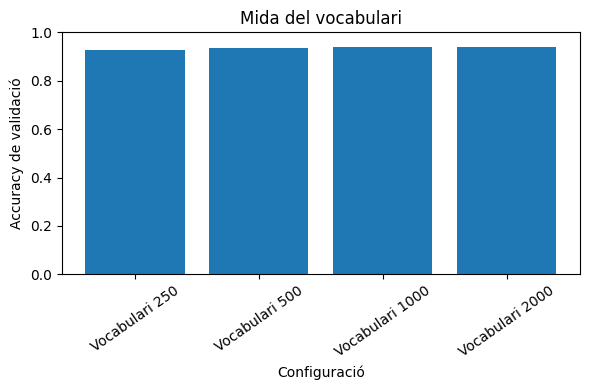

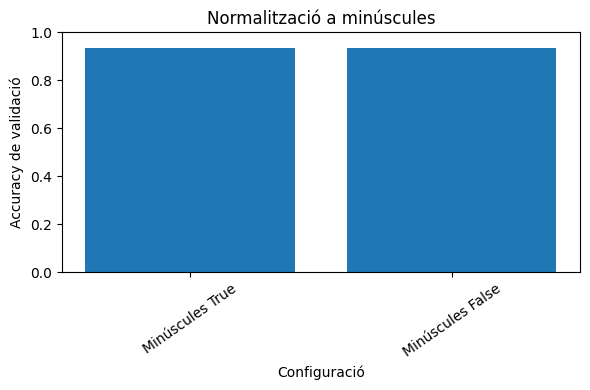

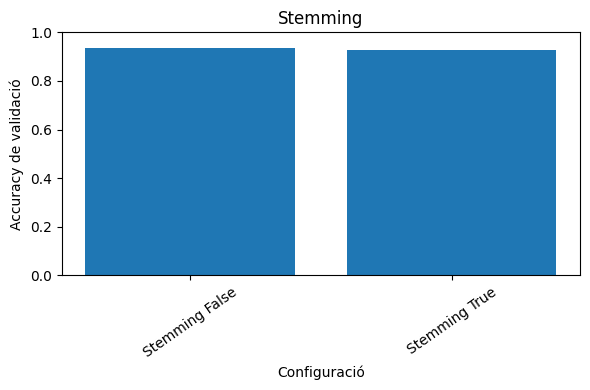

In [27]:
taula_preprocessament = executa_preprocessament()


**Interpretació dels resultats.** Interpretem l'execució guardada amb la llavor 42 i els altres hiperparàmetres constants.

| Vocabulari màxim | Accuracy de validació | Macro-F1 |
|---:|---:|---:|
| 250 | 92,56 % | 0,4733 |
| 500 | 93,56 % | 0,4565 |
| 1000 | 93,89 % | 0,4255 |
| 2000 | 93,89 % | 0,4255 |

Observem que ampliar el vocabulari de 250 a 1000 augmenta l'accuracy, però no el macro-F1. Amb 250 obtenim el macro-F1 més elevat d'aquest contrast: no identifiquem més cobertura lèxica amb una millora uniforme entre classes. Amb 1000 ja cobrim les 830 paraules observades en train, és a dir, 832 IDs amb PAD i UNK. Per això no obtenim tensors ni resultats diferents en passar a 2000.

No observem diferències en activar o desactivar lowercase, perquè els textos ja estan en minúscules. En aplicar stemming amb vocabulari 500, l'accuracy baixa del 93,56 % al 92,89 % i el macro-F1 de 0,4565 a 0,4113. No observem avantatges del stemming en aquesta configuració. Podem interpretar la reducció morfològica com una possible pèrdua de distincions útils, però no hem aïllat quines paraules expliquen la davallada.

**Decisió per continuar.** Respecte a vocabulari 500, amb 1000 guanyem 0,33 punts percentuals d'accuracy i perdem aproximadament 0,0310 de macro-F1. Seleccionem 1000 segons el criteri previst d'accuracy; 2000 no aporta cobertura addicional. Mantenim lowercase activat per coherència amb el baseline, tot i que no produeix un contrast efectiu en aquest corpus, i descartem stemming perquè empitjora totes dues mètriques. Aquesta decisió prioritza encerts globals, no afirma un benefici en totes les classes.


## 5.3. Dimensionalitat dels embeddings

Estudiarem l'efecte de la dimensionalitat dels *embeddings* comparant 32, 64 i 128 dimensions, mantenint constants el vocabulari (500), lowercase activat, stemming desactivat, hidden 64, dropout 0 i la resta de condicions d'entrenament. Augmentar la dimensionalitat permet representacions més expressives, però també incrementa el nombre de paràmetres i el risc de sobreajustament, sense garantir una millora del rendiment.

Addicionalment, completarem l'anàlisi de l'apartat 5.2 comparant la millor configuració individual (E003) amb una combinació dels valors seleccionats mitjançant validació (E009). Aquesta combinació millora lleugerament l'accuracy (93,89 % → 94,11 %) i el macro-F1 (0,4255 → 0,4500), però gairebé duplica el nombre de paràmetres (58.838 → 116.182). Per tant, haurem de valorar si la millora justifica l'augment de complexitat, tenint en compte que no podem atribuir-la a un únic factor.


In [28]:
# Aïllem la dimensió de l'embedding mantenint vocabulari 500 i la resta del model.
configuracions_embeddings = [
    replace(configuracio_referencia, name=f'Embedding {n}', phase='embedding',
            model=replace(configuracio_referencia.model, embedding_dim=n)) for n in [32, 64, 128]
]
plans_apartats.setdefault('embeddings', [asdict(config) for config in configuracions_embeddings])


def executa_embeddings():
    executa_pla('embeddings', configuracions_embeddings)
    return mostra_apartat('embeddings')


def configuracio_comuna():
    previs = models_dun_pla('preprocessament') + models_dun_pla('embeddings')
    if not models_dun_pla('preprocessament') or not models_dun_pla('embeddings'):
        raise ValueError('Primer executarem 5.2 i 5.3, o recuperarem els seus resultats, per fixar el preprocessing comú.')
    # Incloem la combinació addicional només quan ja s'ha mesurat amb validació.
    previs += models_dun_pla('combinacio')
    return config_experiment(millor_identificador(previs))


def executa_combinacio():
    taula = taula_apartat('preprocessament')
    if not models_dun_pla('preprocessament') or not models_dun_pla('embeddings'):
        raise ValueError('Primer completarem els contrastos individuals de 5.2 i 5.3.')
    # Combinem els guanyadors individuals en una prova addicional, sense assumir que funcionaran millor.
    guanyadors = {}
    for contrast in ['vocabulary', 'lowercase', 'stemming']:
        ids = taula.loc[taula.Contrast == contrast, 'Experiment'].tolist()
        guanyadors[contrast] = config_experiment(millor_identificador(ids))
    embedding = config_experiment(millor_identificador(models_dun_pla('embeddings')))
    config = replace(configuracio_referencia, name='Combinació addicional', phase='combined',
                     preprocessing=Ex5Preprocessing(vocab_size=guanyadors['vocabulary'].preprocessing.vocab_size,
                                                     lowercase=guanyadors['lowercase'].preprocessing.lowercase,
                                                     stemming=guanyadors['stemming'].preprocessing.stemming),
                     model=replace(configuracio_referencia.model, embedding_dim=embedding.model.embedding_dim))
    individual = config_experiment(millor_identificador(models_dun_pla('preprocessament') + models_dun_pla('embeddings')))
    referencia = replace(individual, name='Refer\u00e8ncia individual', phase='combined')
    executa_pla('combinacio', [referencia, config])
    return mostra_apartat('combinacio')


Entrenem E007: Embedding 32, llavor 42.
Embedding 32: època 1, validation loss 1.0804, accuracy 0.7167
Embedding 32: època 5, validation loss 0.6583, accuracy 0.8389
Embedding 32: època 10, validation loss 0.5196, accuracy 0.8767
Embedding 32: època 15, validation loss 0.4493, accuracy 0.8967
Embedding 32: època 20, validation loss 0.4142, accuracy 0.9044
Embedding 32: època 25, validation loss 0.4136, accuracy 0.9100
E007 completat: accuracy de validació 0.9067, macro-F1 0.3668.
Entrenem E008: Embedding 128, llavor 42.
Embedding 128: època 1, validation loss 1.0103, accuracy 0.7144
Embedding 128: època 5, validation loss 0.5284, accuracy 0.8611
Embedding 128: època 10, validation loss 0.3470, accuracy 0.9189
Embedding 128: època 15, validation loss 0.2881, accuracy 0.9300
Embedding 128: època 20, validation loss 0.2544, accuracy 0.9389
Embedding 128: època 25, validation loss 0.2787, accuracy 0.9367
E008 completat: accuracy de validació 0.9367, macro-F1 0.4797.


,Experiment,Nom,Validation accuracy,Validation macro-F1,Validation loss,Millor època,Paràmetres,Temps (s),Equivalent
0,E007,Embedding 32,0.906667,0.366759,0.394403,24,19542,5.328487,False
1,E002,Embedding 64,0.935556,0.456458,0.271903,24,37590,5.888175,False
2,E008,Embedding 128,0.936667,0.479694,0.240700,22,73686,6.740046,False


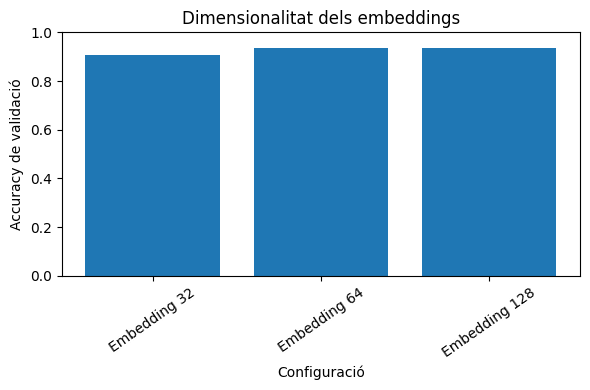

Entrenem E009: Combinació addicional, llavor 42.
Combinació addicional: època 1, validation loss 0.9706, accuracy 0.7189
Combinació addicional: època 5, validation loss 0.5242, accuracy 0.8633
Combinació addicional: època 10, validation loss 0.3418, accuracy 0.9122
Combinació addicional: època 15, validation loss 0.2746, accuracy 0.9367
Combinació addicional: època 20, validation loss 0.2546, accuracy 0.9389
Combinació addicional: època 25, validation loss 0.2911, accuracy 0.9400
E009 completat: accuracy de validació 0.9411, macro-F1 0.4500.


,Experiment,Nom,Validation accuracy,Validation macro-F1,Validation loss,Millor època,Paràmetres,Temps (s),Equivalent
0,E003,Referència individual,0.938889,0.425469,0.277475,24,58838,5.893014,False
1,E009,Combinació addicional,0.941111,0.450033,0.247440,22,116182,6.546827,False


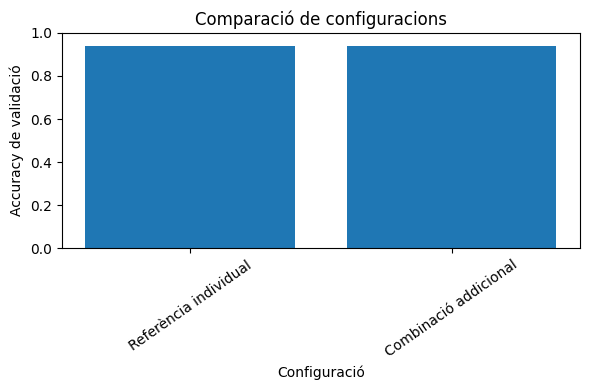

In [29]:
taula_embeddings = executa_embeddings()
taula_combinacio = executa_combinacio()


**Interpretació dels resultats.**

| Dimensió de l'embedding | Accuracy de validació | Macro-F1 | Paràmetres |
|---:|---:|---:|---:|
| 32 | 90,67 % | 0,3668 | 19.542 |
| 64 | 93,56 % | 0,4565 | 37.590 |
| 128 | 93,67 % | 0,4797 | 73.686 |

Observem una millora clara de 32 a 64 dimensions. De 64 a 128 només guanyem 0,11 punts percentuals d'accuracy, equivalents a una classificació correcta addicional entre els 900 exemples de validació, mentre que gairebé dupliquem els paràmetres. Amb 128 obtenim el macro-F1 més elevat del contrast, però no interpretem una diferència tan petita d'accuracy en una sola llavor com un avantatge universal.

En la combinació addicional de vocabulari 1000 i embedding 128 obtenim 94,11 % d'accuracy i macro-F1 0,4500. Hem mesurat aquesta combinació explícitament: supera les configuracions individuals en accuracy, però no el macro-F1 0,4797 del embedding 128 amb vocabulari 500. Distingim, per tant, la configuració seleccionada segons el criteri previst de la millor configuració per a cada mètrica.

**Decisió per continuar.** Amb 128 dimensions guanyem 0,11 punts d'accuracy i 0,0232 de macro-F1 respecte a 64, amb 73.686 davant de 37.590 paràmetres. En combinar vocabulari 1000 i embedding 128 guanyem 0,22 punts d'accuracy respecte al millor contrast individual de vocabulari. Seleccionem aquesta combinació per fixar la representació comuna de CNN, recurrents i l'exploració de self-attention; no continuem cercant dimensions més grans segons test.


## 5.4. Xarxes neuronals convolucionals

Estudiarem si les intencions es poden distingir amb patrons locals de longitud diferent. Provarem kernels 2, 3 i 5 amb 64 filtres: des de parelles de tokens fins a contextos una mica més amplis. Fixarem 64 filtres per disposar de diverses representacions locals amb un cost moderat i evitar canviar alhora amplada i kernel. Detectar fragments recurrents no equival a comprendre totes les relacions lingüístiques de la consulta.

Mantindrem el preprocessing i embedding comuns seleccionats a 5.2–5.3, dropout zero i el mateix entrenament. Primer compararem els kernels amb global max pooling, que destaca l'activació local més forta. Després provarem average pooling amb el millor kernel: agregarem totes les finestres vàlides en lloc de retenir-ne només una. Finalment afegirem una segona convolució a la configuració amb max pooling per aïllar la profunditat; no canviarem simultàniament filtres i pooling.

Utilitzarem convolucions vàlides, sense finestres parcials als marges ni sobre PAD. Renormalitzarem la mitjana pel nombre de finestres vàlides; si no n'hi ha cap, utilitzarem una representació zero. Aquest límit pot perjudicar consultes molt curtes. Compararem accuracy, macro-F1, paràmetres i temps; evitarem una graella de kernels, amplades i profunditats que no permetria atribuir fàcilment els canvis.


In [30]:
def executa_cnn(segona_convolucio=True):
    comuna = configuracio_comuna()
    # Comparem kernels amb el mateix embedding, 64 filtres i max pooling.
    configs = [replace(comuna, name=f'CNN k={k}, max', phase='cnn', class_weights=False,
                        model=Ex5ModelConfig(family='cnn', embedding_dim=comuna.model.embedding_dim,
                                             kernel_size=k, filters=64, pooling='max')) for k in [2, 3, 5]]
    ids = executa_grup(configs)
    millor = config_experiment(millor_identificador(ids))
    # Aïllem el pooling amb el kernel guanyador del contrast anterior.
    configs.append(replace(millor, name=f'CNN k={millor.model.kernel_size}, average', phase='cnn',
                           model=replace(millor.model, pooling='avg')))
    # Comparem profunditat mantenint el kernel i el max pooling de la CNN de referència.
    if segona_convolucio:
        configs.append(replace(millor, name='CNN amb dues convolucions', phase='cnn',
                               model=replace(millor.model, conv_layers=2)))
    executa_pla('cnn', configs)
    return mostra_apartat('cnn')


Entrenem E010: CNN k=2, max, llavor 42.
CNN k=2, max: època 1, validation loss 0.5259, accuracy 0.8744
CNN k=2, max: època 5, validation loss 0.2195, accuracy 0.9467
CNN k=2, max: època 10, validation loss 0.1951, accuracy 0.9522
CNN k=2, max: època 15, validation loss 0.1978, accuracy 0.9567
CNN k=2, max: època 16, validation loss 0.1974, accuracy 0.9578
E010 completat: accuracy de validació 0.9556, macro-F1 0.5501.
Entrenem E011: CNN k=3, max, llavor 42.
CNN k=3, max: època 1, validation loss 0.4597, accuracy 0.8867
CNN k=3, max: època 5, validation loss 0.2100, accuracy 0.9489
CNN k=3, max: època 10, validation loss 0.2058, accuracy 0.9500
CNN k=3, max: època 13, validation loss 0.2011, accuracy 0.9533
E011 completat: accuracy de validació 0.9489, macro-F1 0.5096.
Entrenem E012: CNN k=5, max, llavor 42.
CNN k=5, max: època 1, validation loss 0.5305, accuracy 0.8633
CNN k=5, max: època 5, validation loss 0.3210, accuracy 0.9200
CNN k=5, max: època 9, validation loss 0.3247, accuracy 

,Experiment,Nom,Validation accuracy,Validation macro-F1,Validation loss,Millor època,Paràmetres,Temps (s),Equivalent
0,E010,"CNN k=2, max",0.955556,0.550083,0.187760,12,124374,7.216288,False
1,E011,"CNN k=3, max",0.948889,0.509581,0.197303,9,132566,6.419192,False
2,E012,"CNN k=5, max",0.920000,0.453389,0.320974,5,148950,4.903180,False
3,E013,"CNN k=2, average",0.957778,0.566807,0.199243,13,124374,7.618294,False
4,E014,CNN amb dues convolucions,0.957778,0.567550,0.197363,11,132630,9.365240,False


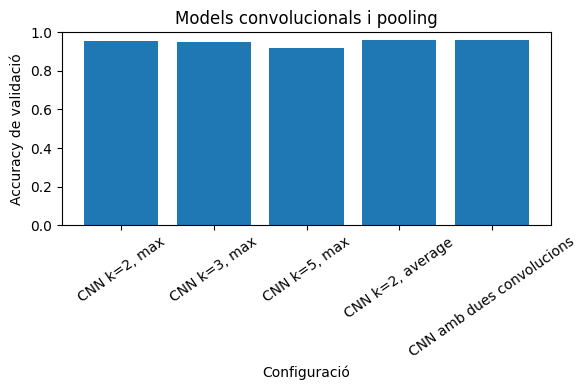

In [31]:
taula_cnn = executa_cnn(segona_convolucio=True)


**Interpretació dels resultats.**

| Configuració CNN | Accuracy de validació | Macro-F1 |
|---|---:|---:|
| Kernel 2, max pooling | 95,56 % | 0,5501 |
| Kernel 3, max pooling | 94,89 % | 0,5096 |
| Kernel 5, max pooling | 92,00 % | 0,4534 |
| Kernel 2, average pooling | 95,78 % | 0,5668 |
| Dues convolucions de kernel 2, max pooling | 95,78 % | 0,5676 |

Obtenim els millors resultats entre kernels amb mida 2. Aquests valors són compatibles amb la utilitat de patrons locals curts; no demostrem, però, que aquesta sigui l'única causa de la diferència.

Identifiquem també una limitació concreta del disseny amb finestres completes: 33 oracions de validació tenen menys de cinc tokens i no poden formar cap finestra vàlida amb kernel 5. Per a aquestes entrades utilitzem una representació agregada zero, independent del text. Considerem aquesta pèrdua d'informació una possible explicació parcial del resultat, sense atribuir-hi causalment tots els errors.

En comparar poolings amb kernel 2, average augmenta lleugerament accuracy i macro-F1. Amb dues convolucions millorem el max pooling d'una capa, però igualem el 95,78 % d'accuracy de la CNN més senzilla amb average. No identifiquem més profunditat amb una millora garantida; la diferència de macro-F1 entre aquestes dues últimes configuracions és molt petita i prové d'una sola llavor.

**Decisió per continuar.** Average pooling i dues convolucions guanyen 0,22 punts d'accuracy respecte a una convolució de kernel 2 amb max pooling: només dos encerts de validació. Seleccionem dues convolucions per l'empat en accuracy i el macro-F1 lleugerament superior, segons el criteri establert. Té 132.630 paràmetres davant de 124.374 de la variant d'una capa amb average; el guany aproximat de 0,0007 de macro-F1 no demostra que aquest cost addicional sigui necessari en general. Els temps de la taula corresponen a aquesta execució, no a un benchmark estable.


## 5.5. Xarxes neuronals recurrents

Estudiarem si representar la seqüència completa ajuda a distingir consultes amb paraules semblants però relacions diferents. Compararem LSTM i GRU: LSTM manté estat ocult i estat de cel·la; GRU utilitza una estructura més compacta i té menys paràmetres en les configuracions provades. Cap d'aquestes diferències garanteix millor classificació.

Provarem LSTM, BiLSTM, GRU, BiGRU, LSTM + attention i BiLSTM + attention amb hidden 128, una capa, dropout zero i el mateix preprocessing, embedding i entrenament. La bidireccionalitat permet representar context anterior i posterior, però augmenta capacitat i cost. Després compararem hidden 64 i 128 només en la recurrent seleccionada: reduirem la capacitat sense multiplicar tota la graella.

Emprarem `pack_padded_sequence` per ignorar PAD i concatenarem els estats finals correctes en les variants bidireccionals. Amb atenció aprendrem una puntuació escalar sobre cada estat recurrent i en calcularem una suma ponderada. Aquesta operació selecciona estats que ja contenen context seqüencial; no calcula interaccions query–key entre tots els tokens com la self-attention.

Limitarem l'atenció inicial a LSTM i BiLSTM per estudiar-la amb i sense context bidireccional. Mantindrem una sola capa i no afegirem GRU amb atenció ni totes les combinacions de dimensions, direccions i profunditats. Així compararem hipòtesis identificables amb un pressupost d'entrenament limitat. Presentarem a continuació una exploració separada de self-attention i informació posicional.


In [32]:
def executa_recurrents():
    comuna = configuracio_comuna()
    # Limitem la comparació a sis variants recurrents amb hidden 128 i sense dropout.
    variants = [('LSTM', False, False), ('LSTM', True, False), ('GRU', False, False),
                ('GRU', True, False), ('LSTM', False, True), ('LSTM', True, True)]
    configs = []
    for tipus, bi, atencio in variants:
        nom = ('Bi' if bi else '') + tipus + (' + attention' if atencio else '')
        configs.append(replace(comuna, name=nom, phase='recurrent', class_weights=False,
                                model=Ex5ModelConfig(family='rnn', embedding_dim=comuna.model.embedding_dim,
                                                     hidden_dim=128, rnn_type=tipus, bidirectional=bi,
                                                     attention=atencio, num_layers=1, dropout=0.0)))
    ids = executa_pla('recurrents', configs)
    mostra_apartat('recurrents')
    millor = config_experiment(millor_identificador(ids))
    # Canviem només hidden a 64 o 128 en la recurrent seleccionada per validació.
    dimensions = [replace(millor, name=f'{millor.name}, hidden={n}', phase='hidden',
                           model=replace(millor.model, hidden_dim=n)) for n in [64, 128]]
    executa_pla('hidden_recurrent', dimensions)
    return mostra_apartat('hidden_recurrent')


Entrenem E015: LSTM, llavor 42.
LSTM: època 1, validation loss 0.7115, accuracy 0.8089
LSTM: època 5, validation loss 0.2282, accuracy 0.9611
LSTM: època 10, validation loss 0.2397, accuracy 0.9622
LSTM: època 11, validation loss 0.2300, accuracy 0.9633
E015 completat: accuracy de validació 0.9622, macro-F1 0.5455.
Entrenem E016: BiLSTM, llavor 42.
BiLSTM: època 1, validation loss 0.4555, accuracy 0.8944
BiLSTM: època 5, validation loss 0.1737, accuracy 0.9678
BiLSTM: època 10, validation loss 0.1668, accuracy 0.9700
BiLSTM: època 13, validation loss 0.1697, accuracy 0.9711
E016 completat: accuracy de validació 0.9700, macro-F1 0.6268.
Entrenem E017: GRU, llavor 42.
GRU: època 1, validation loss 0.6045, accuracy 0.8611
GRU: època 5, validation loss 0.1970, accuracy 0.9611
GRU: època 10, validation loss 0.1912, accuracy 0.9678
GRU: època 12, validation loss 0.1984, accuracy 0.9678
E017 completat: accuracy de validació 0.9667, macro-F1 0.6168.
Entrenem E018: BiGRU, llavor 42.
BiGRU: èpoc

,Experiment,Nom,Validation accuracy,Validation macro-F1,Validation loss,Millor època,Paràmetres,Temps (s),Equivalent
0,E015,LSTM,0.962222,0.545545,0.213090,7,241430,15.165625,False
1,E016,BiLSTM,0.970000,0.626755,0.159224,9,376342,32.191606,False
2,E017,GRU,0.966667,0.616807,0.189771,8,208406,15.443958,False
3,E018,BiGRU,0.970000,0.603677,0.164242,6,310294,22.683791,False
4,E019,LSTM + attention,0.971111,0.616395,0.154033,10,241559,21.805778,False
5,E020,BiLSTM + attention,0.967778,0.608515,0.127268,8,376599,34.602314,False


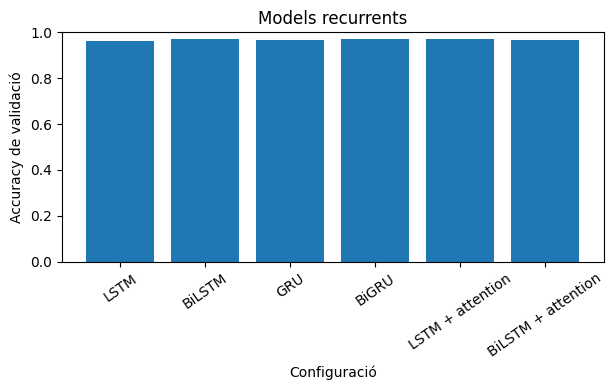

Entrenem E021: LSTM + attention, hidden=64, llavor 42.
LSTM + attention, hidden=64: època 1, validation loss 0.7266, accuracy 0.8178
LSTM + attention, hidden=64: època 5, validation loss 0.2259, accuracy 0.9522
LSTM + attention, hidden=64: època 10, validation loss 0.2005, accuracy 0.9633
LSTM + attention, hidden=64: època 11, validation loss 0.2019, accuracy 0.9622
E021 completat: accuracy de validació 0.9633, macro-F1 0.5152.


,Experiment,Nom,Validation accuracy,Validation macro-F1,Validation loss,Millor època,Paràmetres,Temps (s),Equivalent
0,E021,"LSTM + attention, hidden=64",0.963333,0.515153,0.193637,7,157655,14.472754,False
1,E019,"LSTM + attention, hidden=128",0.971111,0.616395,0.154033,10,241559,21.805778,False


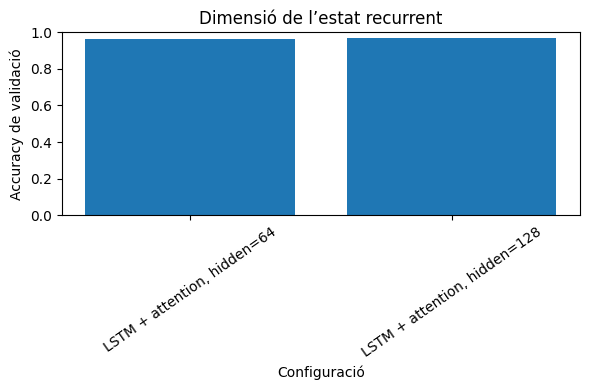

In [33]:
taula_hidden_recurrent = executa_recurrents()
taula_recurrents = taula_apartat('recurrents')


**Interpretació dels resultats.**

| Arquitectura, hidden 128 | Accuracy de validació | Macro-F1 |
|---|---:|---:|
| LSTM | 96,22 % | 0,5455 |
| BiLSTM | 97,00 % | 0,6268 |
| GRU | 96,67 % | 0,6168 |
| BiGRU | 97,00 % | 0,6037 |
| LSTM + attention | 97,11 % | 0,6164 |
| BiLSTM + attention | 96,78 % | 0,6085 |

Observem resultats recurrents superiors als del feedforward i les CNN provades. En afegir bidireccionalitat a LSTM augmentem accuracy i macro-F1; en afegir-la a GRU augmentem accuracy, però el macro-F1 disminueix de 0,6168 a 0,6037. Per tant, no afirmem un benefici uniforme de la bidireccionalitat per a totes les mètriques.

Amb LSTM + attention obtenim la millor accuracy de la comparació principal, 97,11 %. No superem, tanmateix, el macro-F1 de BiLSTM. Afegir attention a BiLSTM redueix accuracy i macro-F1 respecte a BiLSTM sense attention. En el recurrent seleccionat, reduir hidden de 128 a 64 també empitjora els resultats: passem del 97,11 % i 0,6164 al 96,33 % i 0,5152.

Interpretem aquests resultats com a evidència favorable a les representacions seqüencials en les condicions provades, no com una prova causal que l'ordre expliqui tota la millora. També canviem capacitat i nombre de paràmetres entre famílies. No assumim que afegir direccions, attention o complexitat produeixi sempre un guany.

**Decisió per continuar.** LSTM + attention supera LSTM en 0,89 punts d'accuracy i BiLSTM en 0,11 punts, però el seu macro-F1 és inferior al de BiLSTM. Seleccionem LSTM + attention amb hidden 128 segons accuracy i mantenim aquest compromís explícit. L'atenció escalar afegeix 129 paràmetres respecte a LSTM; en canvi, BiLSTM arriba a 376.342 paràmetres davant dels 241.559 de LSTM + attention. Reduir hidden a 64 baixa el cost a 157.655 paràmetres, però perd 0,78 punts d'accuracy en aquesta prova. No atribuïm tota la diferència a la capacitat d'entendre context: també varien capacitat, optimització i representació.


### Comparació exploratòria: self-attention i posicions

Estudiarem una hipòtesi concreta: què aporta informació posicional a un model basat en self-attention? Compararem Embedding → Self-attention → mitjana emmascarada → classificador amb la mateixa arquitectura afegint embeddings posicionals apresos. Sense posicions, la self-attention és equivariant a permutacions i el pooling mitjà en fa una representació invariant a l'ordre; no representa explícitament on apareix cada paraula.

Utilitzarem una sola `nn.MultiheadAttention` de quatre capçals, amb la dimensió comuna seleccionada a 5.3, divisible per quatre. Fixarem dropout zero i loss sense pesos, el mateix preprocessing, llavor 42 i protocol d'entrenament. Inicialitzarem els pesos compartits de manera idèntica. L'única ampliació seran les posicions, limitades a la longitud apresa amb train; també augmentarà el nombre de paràmetres, una limitació del contrast. No afegirem encoder Transformer, models preentrenats ni una cerca de capçals.

Emmascararem claus PAD i les queries PAD abans de fer la mitjana; gestionarem les files completament buides perquè el softmax no rebi només claus excloses. Consultarem la [documentació de MultiheadAttention](https://docs.pytorch.org/docs/stable/generated/torch.nn.MultiheadAttention.html) per interpretar la màscara de claus i les dimensions.


In [34]:
class Ex5SelfAttention(nn.Module):
    def __init__(self, vocab_size, embedding_dim, num_classes, max_length,
                 positional=False, num_heads=4, dropout=0.0):
        super().__init__()
        if embedding_dim % num_heads != 0:
            raise ValueError('La dimensió de l\'embedding ha de ser divisible pel nombre de capçals.')
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        # Utilitzem una sola operació d'atenció, sense afegir un bloc Transformer.
        self.attention = nn.MultiheadAttention(embedding_dim, num_heads, dropout=0.0, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(embedding_dim, num_classes)
        # Inicialitzem les posicions després dels pesos comuns: amb la mateixa llavor
        # les dues variants parteixen dels mateixos embeddings, atenció i classificador.
        # La posici? 0 ?s la primera paraula, no un ID l?xic PAD; emmascarem amb els tokens.
        self.positions = nn.Embedding(max_length, embedding_dim) if positional else None

    def forward(self, ids, lengths=None):
        if ids.size(1) == 0:
            raise ValueError('Necessitem almenys una posició; representem els textos buits amb UNK.')
        mask = ids.ne(0)
        features = self.embedding(ids)  # (batch, longitud, embedding_dim).
        if self.positions is not None:
            if ids.size(1) > self.positions.num_embeddings:
                raise ValueError('La seqüència supera la capacitat posicional apresa amb train.')
            position_ids = torch.arange(ids.size(1), device=ids.device)
            features = features + self.positions(position_ids).unsqueeze(0)
        features = features.masked_fill(~mask.unsqueeze(-1), 0.0)

        # Evitem un softmax amb totes les claus emmascarades en una fila buida.
        # Habilitem una clau zero provisional i després anul·lem totes les seves sortides.
        safe_keys = mask.clone()
        safe_keys[~mask.any(dim=1), 0] = True
        attended, _ = self.attention(features, features, features,
                                     key_padding_mask=~safe_keys, need_weights=False)
        # La màscara de claus no elimina les queries PAD: les excloem també del pooling.
        attended = attended.masked_fill(~mask.unsqueeze(-1), 0.0)
        pooled = attended.sum(dim=1) / mask.sum(dim=1, keepdim=True).clamp(min=1)
        return self.classifier(self.dropout(pooled))  # Logits (batch, num_classes).


# Separem l'exploració dels registres i de la selecció històrica de les tres famílies.
experiments_self_attention = {}
historials_self_attention = {}
models_self_attention = {}


def executa_self_attention():
    comuna = configuracio_comuna()
    preparat = prepara_experiment(comuna)
    rows = []
    for positional in [False, True]:
        nom = 'Self-attention amb posicions' if positional else 'Self-attention sense posicions'
        config = replace(comuna, name=nom, phase='self_attention_exploratory', class_weights=False,
                         model=Ex5ModelConfig(family='self_attention', embedding_dim=comuna.model.embedding_dim,
                                              pooling='avg', dropout=0.0))
        detalls = {'config': asdict(config), 'positional': positional, 'num_heads': 4,
                   'max_length': preparat['tokenizer'].max_length, 'signature': preparat['signature']}
        identificador = 'SA-' + hashlib.sha256(ex5_canonical(detalls).encode('utf-8')).hexdigest()[:12]
        if identificador not in experiments_self_attention:
            # Compartim vocabulari, llavor, loaders, optimitzador i criteri de checkpoint.
            ex5_set_seed(config.training)
            loaders = crea_loaders(preparat, config.training)
            model = Ex5SelfAttention(preparat['tokenizer'].embedding_size, config.model.embedding_dim,
                                     len(EX5_CLASSES), preparat['tokenizer'].max_length,
                                     positional=positional, num_heads=4, dropout=0.0)
            try:
                entrenat = train_model(model, loaders['train'], loaders['val'], config)
                experiments_self_attention[identificador] = {
                    **detalls, 'validation': entrenat['validation'], 'best_epoch': entrenat['best_epoch'],
                    'parameter_count': sum(p.numel() for p in model.parameters() if p.requires_grad),
                    'training_seconds': entrenat['training_seconds']}
                historials_self_attention[identificador] = pd.DataFrame(entrenat['history'])
                models_self_attention[identificador] = entrenat['best_state']
            finally:
                del model
                gc.collect()
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()
        registre = experiments_self_attention[identificador]
        metrics = registre['validation']
        rows.append({'Experiment': identificador, 'Model': nom, 'Posicions': positional,
                     'Embedding': config.model.embedding_dim, 'Capçals': 4, 'Llavor': config.training.seed,
                     'Validation accuracy': metrics['accuracy'], 'Validation macro-F1': metrics['macro_f1'],
                     'Validation loss': metrics['loss'], 'Millor època': registre['best_epoch'],
                     'Paràmetres': registre['parameter_count'], 'Temps (s)': registre['training_seconds']})

    taula = pd.DataFrame(rows)
    display(taula)
    # Representem només mètriques calculades i finites; no generem barres de prova.
    values = taula[['Validation accuracy', 'Validation macro-F1']].to_numpy()
    if np.isfinite(values).all() and np.any(values):
        fig, axes = plt.subplots(1, 2, figsize=(11, 4))
        for ax, metric in zip(axes, ['Validation accuracy', 'Validation macro-F1']):
            ax.bar(['Sense posicions', 'Amb posicions'], taula[metric])
            label = 'Accuracy de validació' if metric == 'Validation accuracy' else 'Macro-F1 de validació'
            ax.set(ylabel=label, ylim=(0, 1), title=label)
        fig.suptitle('Self-attention: efecte de les posicions')
        fig.tight_layout()
        plt.show()
        plt.close(fig)
    return taula


Self-attention sense posicions: època 1, validation loss 0.4748, accuracy 0.8778
Self-attention sense posicions: època 5, validation loss 0.2919, accuracy 0.9367
Self-attention sense posicions: època 8, validation loss 0.3152, accuracy 0.9422
Self-attention amb posicions: època 1, validation loss 0.4159, accuracy 0.8989
Self-attention amb posicions: època 5, validation loss 0.2629, accuracy 0.9411
Self-attention amb posicions: època 9, validation loss 0.3007, accuracy 0.9522


,Experiment,Model,Posicions,Embedding,Capçals,Llavor,Validation accuracy,Validation macro-F1,Validation loss,Millor època,Paràmetres,Temps (s)
0,SA-576289ec528e,Self-attention sense posicions,False,128,4,42,0.931111,0.454764,0.287556,4,175382,7.943222
1,SA-8667f57501d0,Self-attention amb posicions,True,128,4,42,0.941111,0.506494,0.262879,5,181526,9.013733


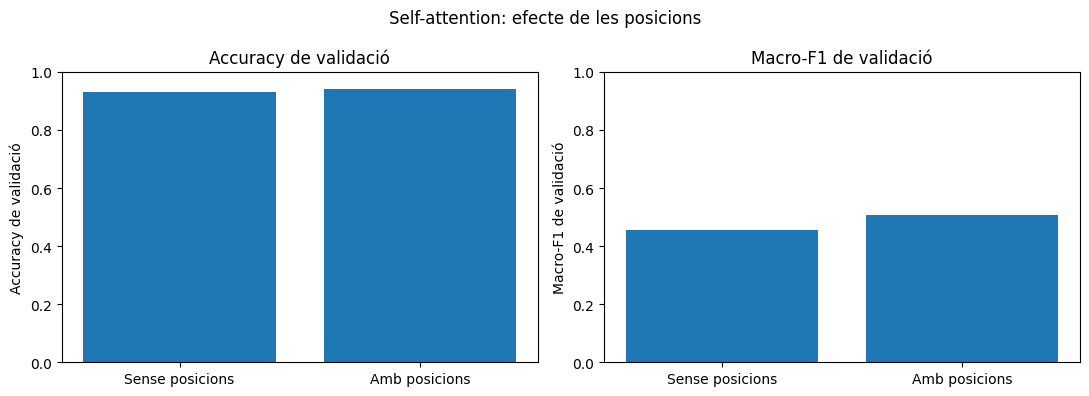

In [35]:
taula_self_attention = executa_self_attention()


**Interpretació exploratòria.** Amb la mateixa llavor i configuració comuna obtenim 93,11 % d'accuracy i macro-F1 0,4548 sense posicions, davant de 94,11 % i 0,5065 amb posicions. El guany és d'1,00 punt percentual, equivalent a nou encerts addicionals sobre els 900 exemples de validació, i aproximadament 0,0517 de macro-F1. La validation loss baixa de 0,2876 a 0,2629.

Dins d'aquesta parella preferim la variant posicional segons les dues mètriques, sense incorporar-la als finalistes històrics. Considerem el resultat compatible amb la utilitat d'informació posicional en aquesta configuració; no demostrem comprensió lingüística general ni significació estadística amb una sola llavor. També afegim 6.144 paràmetres: passem de 175.382 a 181.526, de manera que no aïllem informació posicional de qualsevol efecte de la capacitat addicional.

Les mètriques corresponen als checkpoints de validation loss mínima, a les èpoques 4 i 5, restaurats pel mateix entrenador. No utilitzem les accuracies més altes que apareixen en èpoques posteriors dels logs. Els temps observats són aproximadament 8,21 s i 8,98 s en aquesta execució en CPU; no n'extrapolem un cost universal.


## 5.6. Regularització amb dropout

Estudiarem si reduir la dependència d'activacions concretes millora la generalització. Seleccionarem amb validació una CNN i una recurrent prometedores, en lloc de repetir totes les arquitectures. Compararem dropout 0 com a control, 0,2 com a intensitat moderada i 0,4 com a regularització més forta; no explorarem una graella més densa abans d'observar-ne l'efecte.

Aplicarem dropout després de la representació agregada i abans del classificador. En feedforward se situa després de la capa oculta amb ReLU. En recurrents d'una sola capa no dependrem del dropout intern de LSTM/GRU, que només actua entre capes quan n'hi ha més d'una. Mantindrem el preprocessing, l'arquitectura base, l'optimitzador i el criteri de checkpoint constants.

Llegirem les corbes train/validation juntament amb accuracy i macro-F1 del millor checkpoint. Buscarem trams en què train continua millorant mentre validació s'estanca o empitjora abans de parlar de sobreajustament; una separació entre corbes, per si sola, no en mesura totes les causes. No considerarem el dropout més intens millor per definició.


In [36]:
def executa_dropout():
    cnn = models_dun_pla('cnn')
    recurrents = models_dun_pla('recurrents') + models_dun_pla('hidden_recurrent')
    if not cnn or not models_dun_pla('recurrents') or not models_dun_pla('hidden_recurrent'):
        raise ValueError('Primer completarem 5.4 i 5.5 per seleccionar una CNN i un recurrent.')
    # Seleccionem una base per família abans de comparar les tres intensitats de dropout.
    bases = [config_experiment(millor_identificador(ids)) for ids in [cnn, recurrents]]
    configs = [replace(base, name=f'{base.model.family.upper()}, dropout={valor}', phase='dropout',
                       model=replace(base.model, dropout=valor)) for base in bases for valor in [0.0, 0.2, 0.4]]
    executa_pla('dropout', configs)
    mostra_apartat('dropout')
    mostra_corbes('dropout')


Entrenem E022: CNN, dropout=0.2, llavor 42.
CNN, dropout=0.2: època 1, validation loss 0.6201, accuracy 0.8678
CNN, dropout=0.2: època 5, validation loss 0.2208, accuracy 0.9522
CNN, dropout=0.2: època 10, validation loss 0.2084, accuracy 0.9500
CNN, dropout=0.2: època 15, validation loss 0.2205, accuracy 0.9544
CNN, dropout=0.2: època 17, validation loss 0.2240, accuracy 0.9622
E022 completat: accuracy de validació 0.9556, macro-F1 0.5385.
Entrenem E023: CNN, dropout=0.4, llavor 42.
CNN, dropout=0.4: època 1, validation loss 0.6506, accuracy 0.8667
CNN, dropout=0.4: època 5, validation loss 0.2445, accuracy 0.9456
CNN, dropout=0.4: època 10, validation loss 0.2471, accuracy 0.9511
CNN, dropout=0.4: època 15, validation loss 0.2397, accuracy 0.9567
E023 completat: accuracy de validació 0.9567, macro-F1 0.5289.
Entrenem E024: RNN, dropout=0.2, llavor 42.
RNN, dropout=0.2: època 1, validation loss 0.5659, accuracy 0.8611
RNN, dropout=0.2: època 5, validation loss 0.1752, accuracy 0.9678


,Experiment,Nom,Validation accuracy,Validation macro-F1,Validation loss,Millor època,Paràmetres,Temps (s),Equivalent
0,E014,"CNN, dropout=0.0",0.957778,0.567550,0.197363,11,132630,9.365240,False
1,E022,"CNN, dropout=0.2",0.955556,0.538548,0.196400,13,132630,11.392190,False
2,E023,"CNN, dropout=0.4",0.956667,0.528869,0.206503,11,132630,9.713169,False
3,E019,"RNN, dropout=0.0",0.971111,0.616395,0.154033,10,241559,21.805778,False
4,E024,"RNN, dropout=0.2",0.967778,0.560744,0.149488,7,241559,17.974157,False
5,E025,"RNN, dropout=0.4",0.971111,0.618604,0.150316,11,241559,24.317829,False


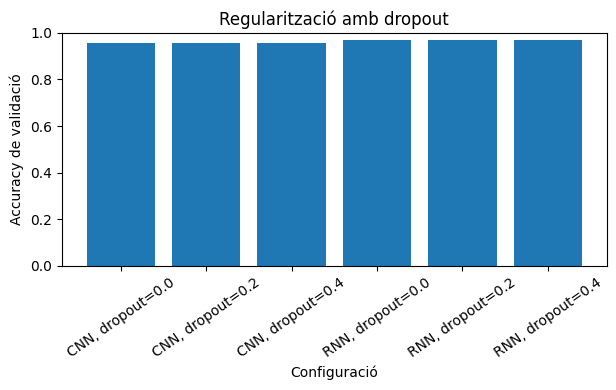

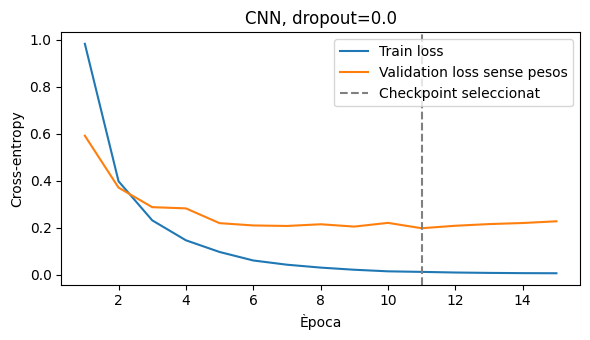

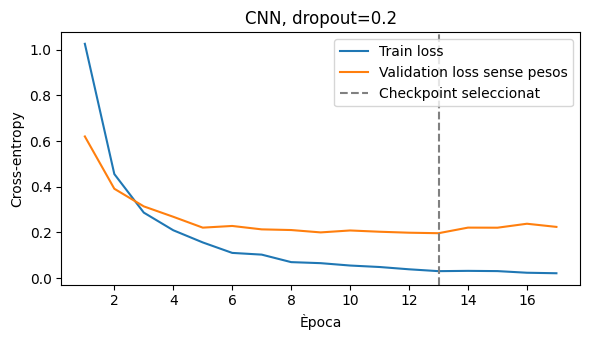

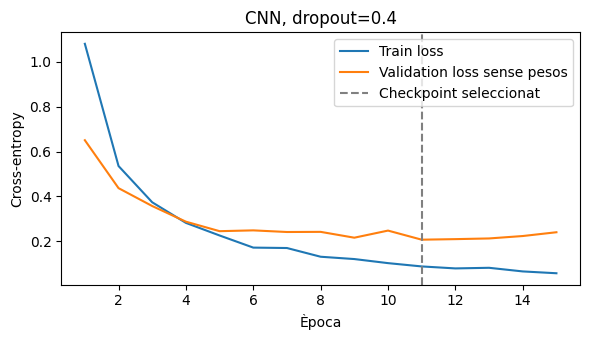

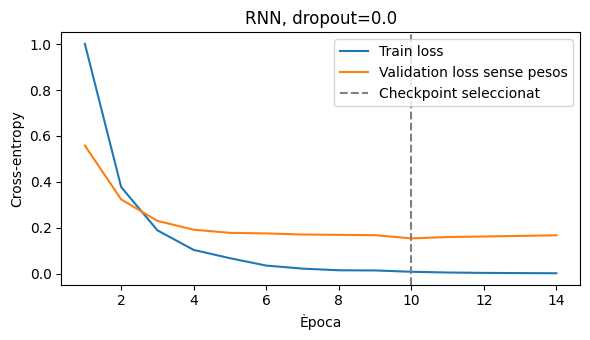

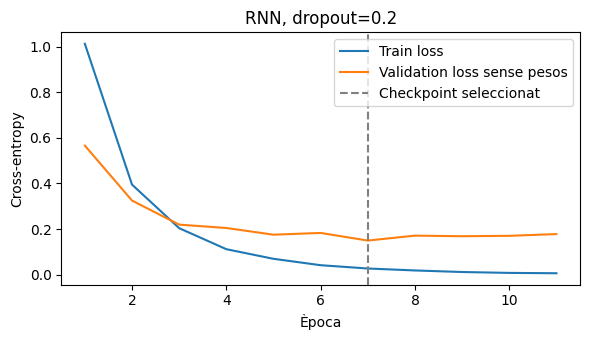

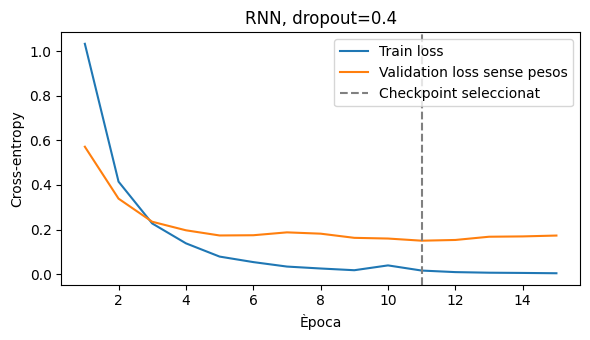

In [37]:
executa_dropout()
taula_dropout = taula_apartat('dropout')


**Interpretació dels resultats.**

| Dropout | Accuracy CNN | Macro-F1 CNN | Accuracy LSTM + attention | Macro-F1 LSTM + attention |
|---:|---:|---:|---:|---:|
| 0 | 95,78 % | 0,5676 | 97,11 % | 0,6164 |
| 0,2 | 95,56 % | 0,5385 | 96,78 % | 0,5607 |
| 0,4 | 95,67 % | 0,5289 | 97,11 % | 0,6186 |

No observem millores en la CNN amb els dos nivells de dropout provats. En LSTM + attention, dropout 0,4 manté el 97,11 % d'accuracy i incrementa només lleugerament el macro-F1, de 0,6164 a 0,6186; dropout 0,2 empitjora totes dues mètriques.

Concloem que l'efecte depèn de l'arquitectura i de la intensitat, i que aquesta comparació amb una sola llavor no estableix una regla general. Interpretem les corbes juntament amb el checkpoint de menor validation loss: no deduïm menys sobreajust només d'una train loss més alta, especialment perquè mantenim dropout actiu a train i desactivat a validació.

**Lectura de les corbes.** En la CNN sense dropout, train loss continua baixant fins a valors molt petits mentre validation loss deixa de millorar i puja després del mínim de l'època 11. En la recurrent sense dropout veiem un patró semblant al voltant del mínim de l'època 10. Considerem aquests trams compatibles amb sobreajustament i justifiquem recuperar el checkpoint. Amb dropout 0,4 en la recurrent també observem repunt de validation loss després del mínim de l'època 11: no afirmem que el dropout hagi eliminat el fenomen.

**Decisió per continuar.** Mantenim dropout zero en la CNN. En la recurrent seleccionem 0,4 perquè empata en accuracy amb zero i millora macro-F1 aproximadament 0,0022. No escollim l'època amb accuracy puntual més alta als logs: comparem els pesos restaurats segons validation loss. Portem aquest model a la comparació de pesos de classe, sense barrejar-hi la self-attention exploratòria.


## 5.7. Balanceig de classes

Estudiarem si reduir el predomini de les classes freqüents en la loss ajuda al rendiment entre classes. Calcularem els pesos com w_c = N / (C * count_c), exclusivament amb train i en el mateix ordre que LabelEncoder. Amb aquesta fórmula igualem la contribució total nominal de cada classe si sumem els seus pesos, però no creem informació ni exemples nous. Aplicarem els pesos a CrossEntropyLoss i mantindrem fixa la configuració del model; no compararem alhora altres esquemes de remostreig o suavització.

Tenim 22 classes, però flight concentra 3023 de 4078 exemples (74,13 %). Identifiquem quatre classes amb un únic exemple i dues amb només dos. Amb els pesos inversos obtenim 185,36 per a una classe d'un exemple, 92,68 per a una de dos i 0,0613 per a flight. Així, assignem a una mostra de classe única un pes 3023 vegades superior al d'una mostra de flight, abans de la normalització de la loss pel pes del batch.

**Limitació dels pesos extrems.** Podem donar molta influència a una sola observació, incloent-hi possibles ambigüitats o errors d'anotació, i afavorir gradients variables o memorització. No hem demostrat que aquests efectes es produeixin en cada classe; expliquem per què la ponderació pot ser inestable quan el suport és tan petit. No assimilarem un macro-F1 agregat més alt a un benefici fiable per a totes les minoritàries.

Compararem el model seleccionat fins a 5.6 amb i sense class weights, mantenint les altres variables constants. Conservarem la validation loss sense pesos per seleccionar checkpoints amb un criteri comú. Consultarem accuracy, macro-F1, recall i suport per classe; no interpretarem el recall zero d'una classe absent de validació com una observació del seu rendiment.

Llegirem accuracy perquè resumeix la proporció d'encerts del conjunt, macro-F1 perquè dona el mateix pes a cada classe i recall amb el seu suport per localitzar guanys i pèrdues. Considerarem aquest balanceig una intervenció sobre l'objectiu d'entrenament, no una eliminació del desbalanceig ni una garantia per a les classes amb una o dues mostres.


In [38]:
def mostra_distribucio_classes():
    pesos = ex5_class_weight_table()
    display(pesos.rename(columns={'class_id': 'Índex', 'label': 'Classe', 'count': 'Exemples',
                                  'frequency': 'Freqüència relativa', 'weight': 'Pes'}))
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.bar(pesos.label, pesos['count'])
    ax.set(xlabel='Intenció', ylabel='Exemples de train (escala logarítmica)', yscale='log', title='Distribució de les classes d’entrenament')
    ax.tick_params(axis='x', rotation=90, labelsize=8)
    fig.tight_layout()
    plt.show()
    plt.close(fig)


def executa_balanceig():
    if not models_dun_pla('dropout'):
        raise ValueError('Primer completarem les comparacions fins a 5.6 abans de seleccionar el model.')
    # Fixem el model prometedor amb validació i canviem únicament els pesos de la loss.
    candidats = [i for i, registre in experiments_ex5.items() if registre['config']['training']['seed'] == 42]
    millor = config_experiment(millor_identificador(candidats))
    configs = [replace(millor, name='Amb pesos' if activat else 'Sense pesos', phase='class_weights',
                       class_weights=activat) for activat in [False, True]]
    executa_pla('pesos', configs)
    mostra_balanceig()


,Índex,Classe,Exemples,Freqüència relativa,Pes
0,0,abbreviation,120,0.029426,1.544697
1,1,aircraft,68,0.016675,2.725936
2,2,aircraft+flight+flight_no,1,0.000245,185.363636
3,3,airfare,333,0.081658,0.556648
4,4,airfare+flight_time,1,0.000245,185.363636
5,5,airline,125,0.030652,1.482909
6,6,airline+flight_no,2,0.000490,92.681818
7,7,airport,14,0.003433,13.240260
8,8,capacity,13,0.003188,14.258741
9,9,cheapest,1,0.000245,185.363636


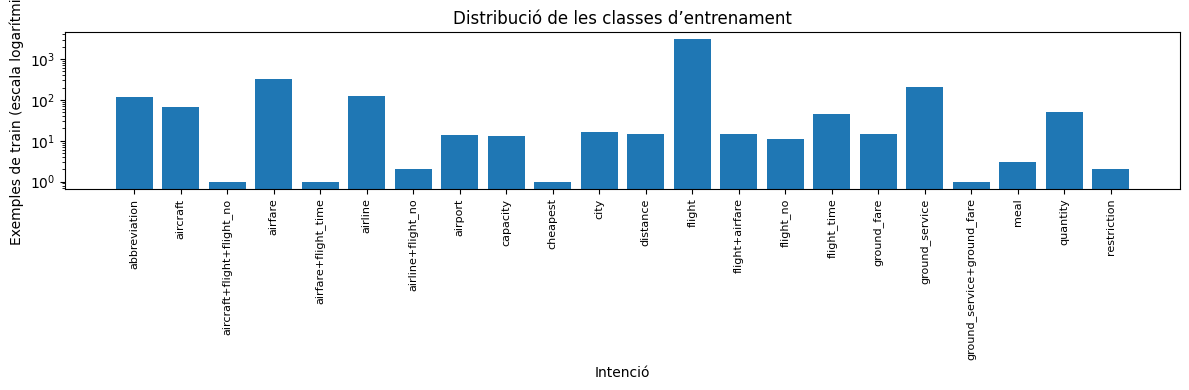

Entrenem E026: Amb pesos, llavor 42.
Amb pesos: època 1, validation loss 1.5095, accuracy 0.7933
Amb pesos: època 5, validation loss 0.2815, accuracy 0.9411
Amb pesos: època 10, validation loss 0.1687, accuracy 0.9622
Amb pesos: època 15, validation loss 0.1507, accuracy 0.9689
Amb pesos: època 17, validation loss 0.1562, accuracy 0.9700
E026 completat: accuracy de validació 0.9711, macro-F1 0.6451.


,Experiment,Nom,Validation accuracy,Validation macro-F1,Validation loss,Millor època,Paràmetres,Temps (s),Equivalent
0,E025,Sense pesos,0.971111,0.618604,0.150316,11,241559,24.317829,False
1,E026,Amb pesos,0.971111,0.645092,0.143451,13,241559,26.904185,False


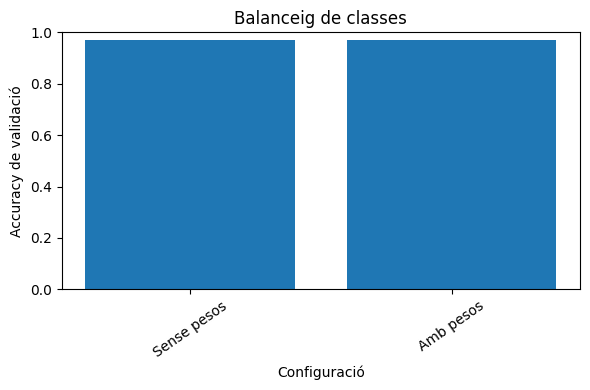

,Classe,Suport de validació,Recall sense pesos,Recall amb pesos,Diferència de recall
0,abbreviation,27,1.000000,1.000000,0.000000
1,aircraft,13,0.923077,1.000000,0.076923
2,aircraft+flight+flight_no,0,0.000000,0.000000,0.000000
3,airfare,90,0.977778,0.977778,0.000000
4,airfare+flight_time,0,0.000000,0.000000,0.000000
5,airline,32,0.875000,0.906250,0.031250
6,airline+flight_no,0,0.000000,0.000000,0.000000
7,airport,6,0.666667,0.833333,0.166667
8,capacity,3,1.000000,1.000000,0.000000
9,cheapest,0,0.000000,0.000000,0.000000


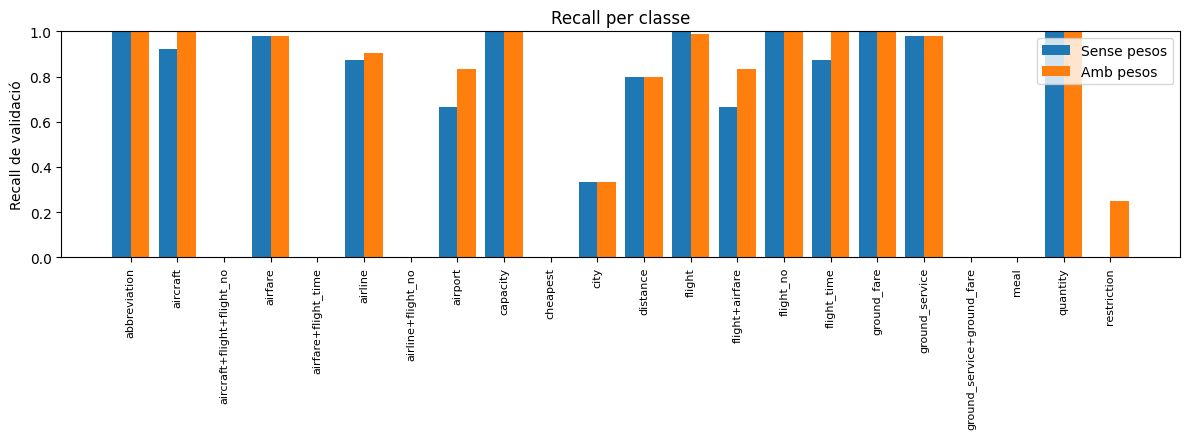

In [39]:
mostra_distribucio_classes()
executa_balanceig()
taula_balanceig = taula_apartat('pesos')


**Interpretació dels resultats.** Amb la LSTM + attention i dropout 0,4 mantenim l'accuracy de validació en 97,11 %, mentre que el macro-F1 augmenta de 0,6186 a 0,6451. Observem una millora agregada segons aquest criteri, no una millora de totes les classes minoritàries.

| Classe | Exemples de validació | Recall sense pesos | Recall amb pesos |
|---|---:|---:|---:|
| aircraft | 13 | 0,9231 | 1,0000 |
| airport | 6 | 0,6667 | 0,8333 |
| flight_time | 8 | 0,8750 | 1,0000 |
| restriction | 4 | 0,0000 | 0,2500 |
| flight | 643 | 0,9953 | 0,9860 |
| meal | 3 | 0,0000 | 0,0000 |

Observem que cadascuna de les quatre primeres millores correspon a una única predicció correcta addicional. En restriction, passar de 0 a 0,25 sembla un augment gran, però només disposem de quatre casos de validació. No interpretem aquests canvis com estimacions precises de generalització.

En flight passem de 640 a 634 encerts sobre 643 exemples. Compensem aquesta pèrdua amb millores en altres classes i mantenim el nombre total d'encerts. En canvi, no millorem el recall de meal, i no podem valorar les cinc classes de train absents de validació. La ponderació no crea exemples nous ni resol la falta de diversitat de les classes amb una o dues mostres.

**Decisió per continuar.** L'increment de macro-F1 és aproximadament 0,0265 sense canviar l'accuracy. Conservem la configuració ponderada com a candidata de la família recurrent perquè resol l'empat segons el criteri secundari. L'arquitectura i els 241.559 paràmetres no canvien; la ponderació modifica l'objectiu i el checkpoint seleccionat. No deduïm una reducció fiable dels errors de totes les classes rares a partir d'un augment agregat.


## 5.8. Comparació global dels models

Mantindrem el criteri històric: prioritzarem accuracy de validació, amb macro-F1 com a criteri secundari i loss per resoldre empats addicionals. L'accuracy respon a l'objectiu de la pràctica i al nombre total de consultes correctes, però pot ocultar errors de classes rares. Per això llegirem sempre macro-F1, recall i suport al costat d'accuracy, sense canviar silenciosament el criteri després de veure els resultats.

Escollirem com a màxim un candidat de cadascuna de les tres famílies originals i el repetirem amb les llavors 42, 123 i 2026. Seleccionarem la família per accuracy mitjana, després macro-F1 mitjà i loss mitjana. Les tres llavors descriuen variabilitat de l'optimització amb la mateixa partició; no equivalen a validació creuada ni corregeixen les repeticions textuals.

Mantindrem la llavor 42 fixada prèviament per al checkpoint final, en lloc de seleccionar la llavor més afavorida per validació o test. Conservarem identificada aquesta selecció històrica de LSTM amb atenció, dropout 0,4 i pesos de classe. La self-attention exploratòria de 5.5 no entra a la cerca original, als seus finalistes ni a test; no utilitzarem el test ja conegut per decidir si substitueix el model final.

En cada execució completa avaluarem una sola vegada el checkpoint fixat a test. Com que aquest conjunt ja s'ha consultat en execucions anteriors, no presentarem la reexecució com una nova avaluació independent ni en farem servir el resultat per redefinir la cerca.


In [40]:
def mostra_comparacio_global(ordena_per='Validation accuracy', ascendent=False):
    if resultats_experiments.empty:
        print('Encara no hem executat experiments definitius per comparar els models.')
        return resultats_experiments
    principals = ['Experiment', 'Nom', 'Família', 'Validation accuracy', 'Validation macro-F1',
                  'Validation loss', 'Paràmetres', 'Temps (s)', 'Llavor']
    columnes = principals + [c for c in resultats_experiments.columns if c not in principals]
    with pd.option_context('display.max_columns', None):
        display(resultats_experiments.sort_values(ordena_per, ascending=ascendent)[columnes].reset_index(drop=True))


def compara_finalistes():
    if not models_dun_pla('pesos'):
        raise ValueError('Primer completarem les comparacions fins a 5.7.')
    configs = []
    # Repetim un candidat per família original; l'exploració de self-attention queda separada.
    for familia in ['feedforward', 'cnn', 'rnn']:
        candidats = [i for i, r in experiments_ex5.items() if r['config']['model']['family'] == familia
                      and r['config']['training']['seed'] == 42]
        if not candidats:
            continue
        millor = config_experiment(millor_identificador(candidats))
        # Mesurem variabilitat d'optimització amb tres llavors, mantenint les particions.
        for llavor in [42, 123, 2026]:
            configs.append(replace(millor, name=f'{familia}, llavor={llavor}', phase='finalist',
                                   training=replace(millor.training, seed=llavor)))
    executa_pla('finalistes', configs)
    return mostra_finalistes()


def mostra_finalistes():
    taula = taula_apartat('finalistes')
    if not models_dun_pla('finalistes'):
        print('Encara no hem completat les tres llavors dels finalistes.')
        return pd.DataFrame()
    # Resumim el rendiment mitjà i la desviació mostral, sense utilitzar mètriques de test.
    resum = taula.groupby('Família').agg(
        accuracy_mitjana=('Validation accuracy', 'mean'), accuracy_std=('Validation accuracy', 'std'),
        macro_f1_mitjana=('Validation macro-F1', 'mean'), macro_f1_std=('Validation macro-F1', 'std'),
        loss_mitjana=('Validation loss', 'mean'), llavors=('Llavor', 'nunique')).reset_index()
    assert resum.llavors.eq(3).all()
    display(resum)
    return resum


def selecciona_model_final(resum=None):
    global seleccio_final, millor_model
    if resum is None:
        resum = mostra_finalistes()
    if resum.empty:
        raise ValueError('Primer completarem i compararem les repeticions dels finalistes.')
    # Mantenim el criteri històric: accuracy mitjana, macro-F1 i després loss de validació.
    familia = resum.sort_values(['accuracy_mitjana', 'macro_f1_mitjana', 'loss_mitjana', 'Família'],
                                 ascending=[False, False, True, True]).iloc[0]['Família']
    taula = taula_apartat('finalistes')
    # Fixem el checkpoint de llavor 42, sense escollir la llavor retrospectivament.
    identificador = taula.loc[(taula['Família'] == familia) & (taula.Llavor == 42), 'Experiment'].iloc[0]
    if avaluacio_final is not None and avaluacio_final['experiment'] != identificador:
        raise RuntimeError('Ja hem consultat test; mantindrem la selecció congelada.')
    seleccio_final = {'experiment': identificador, 'familia': familia, 'llavor': 42,
                      'criteri': 'Mitjana de validació de tres llavors; llavor final 42 fixada prèviament',
                      'resum': resum.to_dict('records')}
    millor_model = recupera_model(identificador)
    print(f'Hem seleccionat {identificador} amb la llavor 42 sense consultar test.')
    return seleccio_final


def avalua_test_final():
    global avaluacio_final
    if seleccio_final is None:
        raise ValueError('Seleccionarem primer el model amb les tres llavors de validaci\u00f3.')
    identificador = seleccio_final['experiment']
    # Reutilitzem l'avaluació final si ja existeix i impedim canviar el model a posteriori.
    if avaluacio_final is not None:
        if avaluacio_final['experiment'] != identificador:
            raise RuntimeError('No canviarem el model després de consultar test.')
        return avaluacio_final
    config = config_experiment(identificador)
    if config.training.seed != 42:
        raise ValueError('Utilitzarem la llavor 42, fixada abans de veure test.')
    model = recupera_model(identificador)
    dispositiu = ex5_device(config.training)
    model.to(dispositiu)
    tokenitzador = prepara_experiment(config)['tokenizer']
    # Transformem test amb el vocabulari del model seleccionat, sense reajustar res.
    part = tokenitzador.transform(EX5_DATA['test'])
    loader = DataLoader(TensorDataset(part['ids'], part['lengths'], part['labels']),
                         batch_size=config.training.batch_size, shuffle=False)
    metrics = evaluate_model(model, loader, dispositiu)
    avaluacio_final = {'experiment': identificador, 'metrics': metrics, 'seleccio': copy.deepcopy(seleccio_final)}
    del model
    return avaluacio_final


def mostra_test_final():
    if avaluacio_final is None:
        print('Encara no hem avaluat el model final sobre test.')
        return
    metrics = avaluacio_final['metrics']
    display(pd.DataFrame([{'Experiment': avaluacio_final['experiment'], 'Test accuracy': metrics['accuracy'],
                           'Test macro-F1': metrics['macro_f1'], 'Test loss': metrics['loss']}]))
    matriu = np.asarray(metrics['confusion_matrix'])
    if matriu.size == 0 or not np.isfinite(matriu).all() or matriu.sum() == 0:
        print('Encara no disposem d’una matriu de confusió vàlida.')
        return
    fig, ax = plt.subplots(figsize=(11, 9))
    imatge = ax.imshow(matriu, cmap='Blues')
    ax.set(xticks=np.arange(len(EX5_CLASSES)), yticks=np.arange(len(EX5_CLASSES)),
           xticklabels=EX5_CLASSES, yticklabels=EX5_CLASSES, xlabel='Predicció', ylabel='Etiqueta real', title='Matriu de confusió de test')
    ax.tick_params(axis='x', rotation=90, labelsize=8)
    ax.tick_params(axis='y', labelsize=8)
    fig.colorbar(imatge, ax=ax)
    fig.tight_layout()
    plt.show()
    plt.close(fig)


In [41]:
resum_finalistes = compara_finalistes()


Entrenem E027: feedforward, llavor=123, llavor 123.
feedforward, llavor=123: època 1, validation loss 1.0055, accuracy 0.7233
feedforward, llavor=123: època 5, validation loss 0.4620, accuracy 0.8922
feedforward, llavor=123: època 10, validation loss 0.2989, accuracy 0.9289
feedforward, llavor=123: època 15, validation loss 0.2594, accuracy 0.9389
feedforward, llavor=123: època 20, validation loss 0.2440, accuracy 0.9389
feedforward, llavor=123: època 22, validation loss 0.2522, accuracy 0.9378
E027 completat: accuracy de validació 0.9389, macro-F1 0.4518.
Entrenem E028: feedforward, llavor=2026, llavor 2026.
feedforward, llavor=2026: època 1, validation loss 0.9510, accuracy 0.7444
feedforward, llavor=2026: època 5, validation loss 0.4538, accuracy 0.8922
feedforward, llavor=2026: època 10, validation loss 0.3278, accuracy 0.9144
feedforward, llavor=2026: època 15, validation loss 0.2778, accuracy 0.9322
feedforward, llavor=2026: època 19, validation loss 0.2961, accuracy 0.9344
E028 

,Família,accuracy_mitjana,accuracy_std,macro_f1_mitjana,macro_f1_std,loss_mitjana,llavors
0,cnn,0.960000,0.003849,0.561711,0.023041,0.189733,3
1,feedforward,0.937407,0.004626,0.439979,0.018938,0.254319,3
2,rnn,0.972963,0.002313,0.653071,0.020918,0.142747,3


In [42]:
seleccio_final = selecciona_model_final(resum_finalistes)
mostra_comparacio_global()


Hem seleccionat E026 amb la llavor 42 sense consultar test.


,Experiment,Nom,Família,Validation accuracy,Validation macro-F1,Validation loss,Paràmetres,Temps (s),Llavor,Arquitectura,Vocabulari,Minúscules,Stemming,Vocabulari real,Longitud màxima,Embedding,Hidden,Kernel,Pooling,Bidireccional,Attention,Dropout,Pesos de classe,Millor època,Temps addicional (s),Màxim d’èpoques,Learning rate,Patience,Equivalent
0,E031,"rnn, llavor=123",rnn,0.975556,0.676803,0.141663,241559,39.991667,123,LSTM + attention,1000,True,False,832,48,128,128,NaN,attention,False,True,0.4,True,21,39.991667,25,0.001,4,False
1,E032,"rnn, llavor=2026",rnn,0.972222,0.637316,0.143128,241559,28.737119,2026,LSTM + attention,1000,True,False,832,48,128,128,NaN,attention,False,True,0.4,True,13,28.737119,25,0.001,4,False
2,E026,Amb pesos,rnn,0.971111,0.645092,0.143451,241559,26.904185,42,LSTM + attention,1000,True,False,832,48,128,128,NaN,attention,False,True,0.4,True,13,26.904185,25,0.001,4,False
3,E025,"RNN, dropout=0.4",rnn,0.971111,0.618604,0.150316,241559,24.317829,42,LSTM + attention,1000,True,False,832,48,128,128,NaN,attention,False,True,0.4,False,11,24.317829,25,0.001,4,False
4,E019,LSTM + attention,rnn,0.971111,0.616395,0.154033,241559,21.805778,42,LSTM + attention,1000,True,False,832,48,128,128,NaN,attention,False,True,0.0,False,10,21.805778,25,0.001,4,False
5,E016,BiLSTM,rnn,0.970000,0.626755,0.159224,376342,32.191606,42,BiLSTM,1000,True,False,832,48,128,128,NaN,final hidden,True,False,0.0,False,9,32.191606,25,0.001,4,False
6,E018,BiGRU,rnn,0.970000,0.603677,0.164242,310294,22.683791,42,BiGRU,1000,True,False,832,48,128,128,NaN,final hidden,True,False,0.0,False,6,22.683791,25,0.001,4,False
7,E024,"RNN, dropout=0.2",rnn,0.967778,0.560744,0.149488,241559,17.974157,42,LSTM + attention,1000,True,False,832,48,128,128,NaN,attention,False,True,0.2,False,7,17.974157,25,0.001,4,False
8,E020,BiLSTM + attention,rnn,0.967778,0.608515,0.127268,376599,34.602314,42,BiLSTM + attention,1000,True,False,832,48,128,128,NaN,attention,True,True,0.0,False,8,34.602314,25,0.001,4,False
9,E017,GRU,rnn,0.966667,0.616807,0.189771,208406,15.443958,42,GRU,1000,True,False,832,48,128,128,NaN,final hidden,False,False,0.0,False,8,15.443958,25,0.001,4,False


,Experiment,Test accuracy,Test macro-F1,Test loss
0,E026,0.954955,0.593729,0.206094


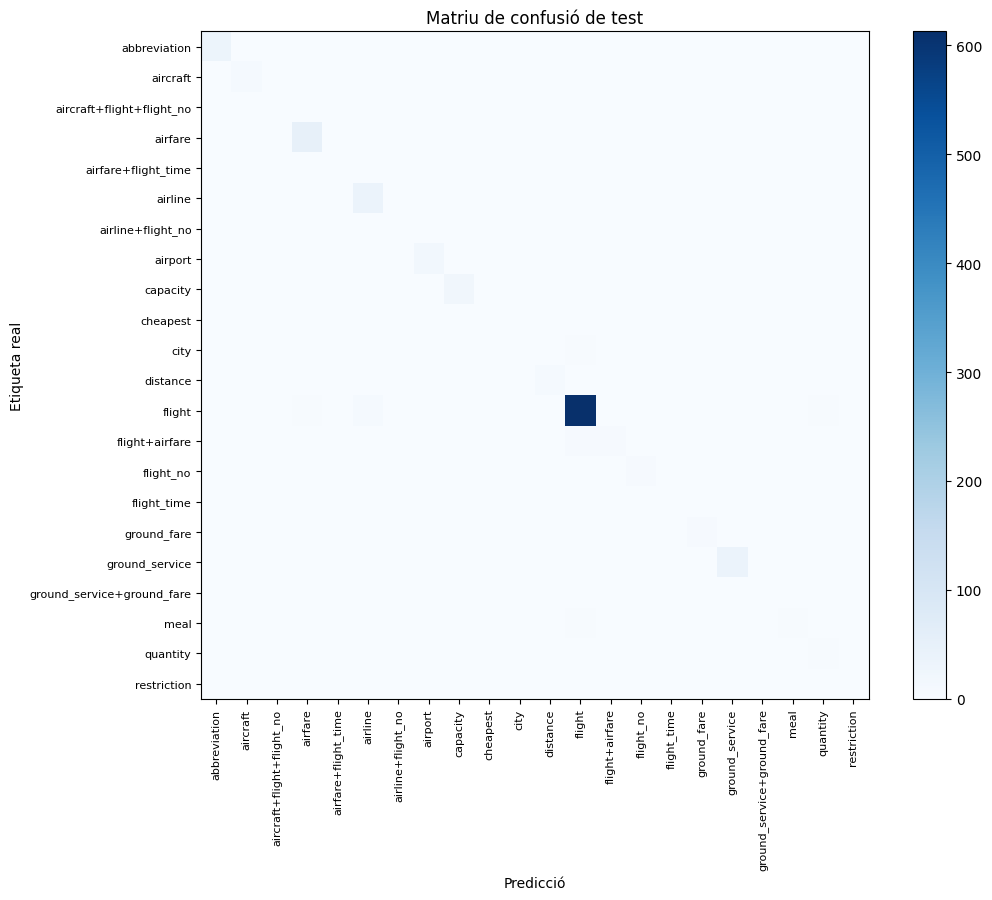

In [43]:
avaluacio_final = avalua_test_final()
mostra_test_final()


**Interpretació de la comparació global.** En repetir un finalista per família amb les llavors 42, 123 i 2026, obtenim:

| Finalista | Accuracy mitjana de validació ± desviació | Macro-F1 mitjà ± desviació |
|---|---:|---:|
| Feedforward | 93,74 % ± 0,46 punts percentuals | 0,4400 ± 0,0189 |
| CNN de dues convolucions | 96,00 % ± 0,38 punts percentuals | 0,5617 ± 0,0230 |
| LSTM + attention, dropout 0,4 i pesos de classe | 97,30 % ± 0,23 punts percentuals | 0,6531 ± 0,0209 |

Observem el millor rendiment mitjà en el finalista recurrent, entre les configuracions provades i amb aquest protocol. Les desviacions descriuen variabilitat d'entrenament entre tres llavors; no quantifiquen el biaix de les particions ni tota la incertesa de generalització.

Seleccionem la LSTM unidireccional amb attention, vocabulari màxim 1000, embedding 128, hidden 128, dropout 0,4 i pesos de classe. Utilitzem la llavor 42 fixada prèviament, encara que una altra llavor obtingui més accuracy de validació. No seleccionem retrospectivament la millor llavor segons test.

En l'avaluació final d'aquesta execució obtenim 848/888 encerts, accuracy 95,50 % i macro-F1 0,5937. Interpretem conjuntament aquestes mètriques i el suport de cada classe: l'accuracy està dominada per les classes freqüents, mentre que macro-F1 dona el mateix pes a les 22 classes fixades, incloses les que no tenen suport en la partició avaluada.

**Cost i criteri alternatiu.** El model seleccionat té 241.559 paràmetres, davant dels 132.630 de la CNN finalista i 116.182 del feedforward. Amb llavor 42 observem aproximadament 26,87 s, 8,93 s i 6,33 s d'entrenament, respectivament, a l'execució guardada en CPU; aquests temps depenen de les èpoques i de l'entorn. Acceptem el cost més alt per l'avantatge de validació observat, sense convertir-lo en una regla sobre totes les arquitectures.

Si ordenem només els tres finalistes ja repetits per macro-F1 mitjà, també seleccionem el recurrent: 0,6531 davant de 0,5617 i 0,4400. Això no equival a repetir tota la selecció prioritzant macro-F1 des del principi. En feedforward, per exemple, aquest criteri preferiria vocabulari 500 i embedding 128, amb macro-F1 0,4797, a la combinació escollida per accuracy. No hem repetit aquest candidat alternatiu amb tres llavors ni canviem retrospectivament el protocol. Mantenim la selecció històrica identificada i la self-attention exploratòria fora d'aquest test.


## 5.9. Conclusions

**Representació del text.** Hem après que més cobertura lèxica no implica un guany equilibrat entre classes. Amb vocabulari 1000 cobrim les 830 paraules de train i millorem accuracy respecte a 250, però el macro-F1 més alt del contrast correspon al límit petit. Ampliar a 2000 no canvia els tensors. Lowercase no és un experiment informatiu en aquests textos ja normalitzats; stemming dona un resultat negatiu que conservem, perquè mostra que reduir formes morfològiques no ajuda necessàriament a distingir intencions.

**Dimensionalitat i cost.** El salt de 32 a 64 dimensions aporta un guany clar en la comparació feta. De 64 a 128 només afegim un encert de validació i gairebé dupliquem els paràmetres del feedforward, tot i millorar macro-F1. Seleccionem la combinació de vocabulari 1000 i embedding 128 després de mesurar-la explícitament. No deduïm que cada millor valor individual formi automàticament la millor combinació ni que haguem trobat un òptim global.

**Patrons locals i seqüencials.** Les CNN funcionen millor amb kernels curts en aquestes proves. La política de finestres completes limita els kernels grans en oracions curtes; no interpretem tots els errors com una qüestió lingüística. Una capa amb average pooling i dues amb max pooling empaten en accuracy, de manera que més profunditat no garanteix millor resultat. Les recurrents obtenen més accuracy, però també canvien capacitat i cost: no aïllem causalment l'ordre com a única explicació.

**Bidireccionalitat i atenció.** La bidireccionalitat millora accuracy de LSTM i GRU, però no totes les seves mètriques: en GRU disminueix macro-F1. L'atenció sobre estats recurrents ajuda LSTM i no ajuda BiLSTM. Escollim LSTM + attention per accuracy i observem que BiLSTM manté més macro-F1 en el contrast sense regularització. Aprenem a valorar la representació concreta i les mètriques conjuntament, en lloc d'afegir complexitat per defecte.

**Regularització i sobreajustament.** Les corbes mostren trams en què train millora mentre validació s'estanca o empitjora; recuperem els pesos de validation loss mínima. Dropout no millora la CNN provada. En LSTM + attention, 0,4 manté accuracy i augmenta només lleugerament macro-F1. No eliminem tot el sobreajustament ni afirmem una intensitat universal: comparem cada família i distingim les condicions de train i eval.

**Balanceig i classes rares.** La ponderació manté 97,11 % d'accuracy i augmenta macro-F1 de 0,6186 a 0,6451, amb guanys en algunes classes i pèrdua de recall en flight. No millorem totes les minoritàries. Els pesos elevats poden donar molta influència a una o dues mostres i no substitueixen diversitat de dades; tampoc podem validar un benefici en classes sense suport de validació.

**Selecció i rendiment.** En els finalistes originals obtenim accuracy mitjana de 93,74 % en feedforward, 96,00 % en CNN i 97,30 % en la recurrent ponderada, amb les tres llavors establertes. Mantenim la selecció històrica de LSTM + attention, dropout 0,4, pesos i llavor 42; en el test ja avaluat obté 95,50 % d'accuracy i macro-F1 0,5937. Acceptem més paràmetres i temps per la millora observada en validació, però no confonem encerts globals amb un rendiment uniforme entre classes.


**Self-attention i posicions.** En la parella exploratòria, afegir posicions passa de 93,11 % a 94,11 % d'accuracy i de 0,4548 a 0,5065 de macro-F1 en validació. Sense posicions, l'agregació no representa explícitament l'ordre; amb posicions permetem distingir-lo. Observem un guany sota aquesta configuració, amb una llavor i 6.144 paràmetres addicionals, i no el generalitzem a tots els mecanismes d'atenció. Distingim aquesta operació de l'atenció escalar sobre estats recurrents. No utilitzem aquests resultats per substituir el checkpoint històric ni per repetir-ne l'avaluació de test.

**Abast experimental.** Les comparacions controlades ens permeten estudiar factors concrets amb un cost limitat, però no cobreixen totes les interaccions ni estableixen significació estadística. Tres llavors només descriuen part de la variabilitat. Conservem les particions, les exclusions i la selecció històrica; no utilitzem el test conegut per justificar cap decisió de l'exploració addicional.


**Limitacions del protocol.** Conservem les quatre exclusions d'etiquetes que afecten cinc exemples de test; les mètriques descriuen els 888 casos retinguts, no els 893 originals ni la detecció d'intencions desconegudes. Conservem també els 93 textos compartits entre train i validació (104 files) i els 10 textos compartits entre train i test. No presentem, per tant, les mètriques com una estimació lliure de biaixos.

Considerem especialment fràgils les conclusions de classes amb una o dues mostres de train i de recalls calculats amb molt pocs casos. Tenim cinc classes de train absents de validació; no podem validar-hi un benefici del balanceig. El macro-F1 sobre el conjunt fix de 22 classes inclou zeros quan no hi ha suport, una decisió que també hem de considerar en comparar-lo amb accuracy.

Recordem que repetir tres llavors només descriu una part de la variabilitat i no elimina el solapament textual. Conservem, a més, la limitació històrica d'haver consultat test en execucions anteriors dels exercicis previs; en aquesta bateria no l'hem utilitzat per seleccionar configuracions. Mantindrem ara el protocol fix i no repetirem la cerca segons els resultats de test.

Per al lliurable, prioritzarem les comparacions breus i els gràfics pertinents de cada apartat, mantenint les taules detallades al notebook com a traçabilitat. Reservarem espai per justificar aquestes limitacions sense superar les deu pàgines de l'informe.

Limitem la cerca a contrasts d'un factor, una combinació addicional i les arquitectures declarades; no explorem totes les interaccions entre preprocessing, capacitat i regularització. La self-attention afegida és una parella exploratòria amb una llavor, posterior al test històric, i queda fora de la seva selecció. Tampoc separem el benefici de la informació posicional del dels paràmetres addicionals amb un control de capacitat específic. No disposem de proves de significació ni d'una partició textual independent per confirmar-ne la generalització.



<h1><a name="section-four"> 4. Lliurable </a></h1>

Heu d'entregar un document PDF de com a **màxim 10 pàgines** que incloga els resultats de tots els exercicis així com una explicació de cadascun dels resultats i de la modificació que heu fet. L'estructura del document és:

1. Introducció.
2. Experiments i Resultats (amb raonament).
3. Conclusions.

No cal que afegiu el vostre codi al document, podeu entregar el *notebook* juntament amb el document.

 ---